In [8]:
%load_ext autoreload
%autoreload 2

import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
import CoolProp.CoolProp as CP
import thermo as thermo
import time as timer
import cProfile
import pstats
import yaml
import copy
import sys
from scipy.optimize import brentq
from thermal import *

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [9]:
# HeatingElement and TinlessSimulation have been extracted to
# thermal/tinless.py and are imported via `from thermal import *`.
# This cell is intentionally left as a stub — do NOT redefine the
# classes here, as running this cell would overwrite the package
# version for the remainder of the kernel session.


In [106]:
yaml_content = """
# Tinless System Model - Simulation Input
# Graphite storage block radiating directly to a central powerstick (no tin piping)

# -- General Simulation Parameters --------------------------------------------
end_time: 240000          # total simulation time [s]  (50 hr discharge)
dt_short: 600              # timestep [s] — used for the first dt_short_duration seconds
dt_medium: 900             # timestep [s] — used when shade is active and not clamped
dt_long: 1800               # timestep [s] — used when shade is clamped at f_shade_max
dt_short_duration: 3600    # seconds of real time to use dt_short at the start
sub_steps: 5              # FD sub-steps per time step (stability)
T_sur: 300                # surroundings temperature [K]
block_heat_loss_bool: False
liner_bool: True         # True = TaC liner, False = no liner
liner_material: graphite      # tac = TaC-coated inner face; graphite = uncoated graphite
shade_bool: True       # True = insulating graphite shade, False = no shade
print_outputs_bool: True

# -- Emissivity Table ---------------------------------------------------------
# Format per band: [[wl_min, wl_max], emis_active, emis_bare, emis_inactive]
# Use range format to allow time-varying tables (e.g. panels offline during charging)
emissivity_tables:
  - range: [0, end_time-1]
    value:
      - [[0.1, 1.24], 0.9, 0.02, 0.02]   # below bandgap
      - [[1.24, 20.0], 0.015, 0.02, 0.02]  # above bandgap

# -- Storage Block ------------------------------------------------------------
storage:
  avg_flux: 10            # average power density to extract [W/cm^2]
  duration_hr: 50          # discharge duration [hr]
  T_min: 1873              # minimum (empty) block temperature [K]
  block_temp_range: 500    # operating temperature swing [K]
  L: 3                   # axial length [m]
  block_height: 10       # block + heater + shade height [m]; null -> L. Stick + liner (length L) hang top-aligned
  th_ins: 0.0              # outer-wall insulation thickness [m]
  num_ax_segments: 20      # TOTAL block rings over block_height (split lower/active zone by height)
  num_rad_segments: 5

# -- Powerstick ---------------------------------------------------------------
powerstick:
  side_len: 0.13           # square cross-section side length [m]
  area_ratio: 10           # r_in / r_ps_eff. IGNORED when shade_bool: true (cavity = minimum that fits the shade around the liner)
  cooling_temp: 323        # powerstick cooling temperature [K]
  f_bare: 0.05
  f_active: .9
  liner_side_len: 0.25     # square side length of liner [m]; r_liner = 2*side_len/pi
  liner_thickness: 0.005  # liner wall thickness [m]
  tungsten_foil: false   # add W foil between TaC face and powerstick

# -- Insulating Shade -------------------------------------------------------
# Octagonal shade surrounding the liner.
# liner_to_shade_perimeter_ratio = shade_perimeter / liner_perimeter
# r_shade_eff = ratio * 2 * liner_side_len / pi  (equivalent circular radius)
# f_shade is found by bisection to hold cell flux at storage.avg_flux.
# shade_bool=False disables the shade.
shade:
  liner_to_shade_perimeter_ratio: 1.707  # 1 + sqrt(2)/2; octagon with L = liner_side_len
  thickness: 0.0391          # shade wall thickness [m]
  surface_emissivity: 0.9         # emissivity of shade surfaces
  num_conduction_layers: 1 # unused: shade conduction uses the exact integral of k(T) (axial model); legacy model uses 1 layer
  corner_gap: 0.003175     # gap between adjacent panel edges at fully-closed [m] (= 1/8 in)
  outer_foil: false          # true = W foil on shade outer face (adds radiative resistance)
  model: vanes               # axial model only: vanes = 8 centre-pivoted vanes in a square cavity (closed/open
                             #   limits ray-traced; setpoint held when between them) | porous = thin porous sheet
  vane_clearance: 0.005      # [m] vanes: min clearance to liner/wall when open. Vane length = liner side +
                             #   sqrt(2)*clearance; cavity side >= 4*vane length + 2*clearance (bore enlarged if needed)
  
# -- Decoupled block height: liner bottom, cavity ends, axial radiation -------
# Defaults below reproduce the original model (block_height = L, local per-segment
# radiation, no liner-bottom model). See decoupled_block_height_brief.md.
liner_bottom:
  enabled: true            # true -> liner-bottom plate + RGF pad model, bottom-cap flux reported
  rgf_thickness: 0.05      # RGF pad on external bottom of liner [m]
  rgf_outer_emissivity: null   # pad underside emissivity; null -> shade.surface_emissivity
  include_flux_to_cells_in_power: false  # LB -> lowest cell flux always reported; added to P only if true

bottom_cap:
  temperature: null         # [K]; null -> powerstick.cooling_temp. Emissivity = emis_bare (gas director)

cavity_ends:                # floor + ceiling: thin graphite over Thermax, reradiating
  emissivity: null          # null -> graphite emissivity gr_emis(T)
  ceiling_gap: 0.01         # radial gap ceiling inner edge -> liner outer wall [m] (treated closed)

radiation:
  axial: true              # true -> full-height ring-to-ring enclosure (shade per shade.model); false -> local per segment
  vf_method: analytic       # unshaded only: analytic (exact where possible) | montecarlo. Shaded cavity is always ray-traced
  vf_rays: 65536            # rays/surface, Monte Carlo view factors (Sobol; ~1% worst-entry error, target 2%)
  vane_rays: 16384          # rays/surface for the vane closed/open view factors (heat within ~0.02% of 2^18)
  vf_cache_dir: .vf_cache   # cache traced view factors on disk (null = no cache)

# -- Heater ------------------------------------------------------------------
# Central cylindrical resistive heating element used during charging.
# The heater spans the block height; max power = max_power_per_m x block_height.
# Phase 1: max power supplied; T_heater rises as graphite warms.
# Phase 2: T_heater reaches max_temperature; power reduces to hold that temp.
# Heating stops when block T_avg reaches T_min + block_temp_range.
heater:
  side_len: 0.15            # m   (heater rod side length)
  area_ratio: 4.5           # D_cavity / D_heater; heater cavity also sets the tank layout (tank.py)
  max_temperature: 2873     # K   (maximum heater surface temperature)
  max_power_per_m: 250000   # W/m (maximum electrical power per m of heater length)
  emissivity: 0.85           # gray-body emissivity of heater surface
  charge_hr: 30           # target charge time [h] for the heater-cavity search; null -> end_time

# -- System-scale steel tank (thermal/tank.py; steel_tank_system_brief.md) ----
# Builds the plant around the per-stick results: checkerboard hot zone, API 650
# tank, Thermax, graphite->oxide columns, finned floor, foundation, losses, capex.
# Temperatures in C. Every cost is a PLACEHOLDER [low, central, high].
tank:
  P_rated: 25.0e+6           # W_e plant rating; N_ps = ceil(P_rated / P_stick), P_stick = discharge-average power
  duration_hr: 50           # h; energy mismatch vs N_ps * E_stick_e is reported, not resized
  T_amb: 15.0               # C annual mean (loss calc)
  T_air_design: 40.0        # C design-day floor-air inlet (floor check)
  t_side: 1.0               # m Thermax side wall
  t_top: 1.5                # m Thermax roof
  L_bot: 2.0                # m bottom stack (columns + Thermax)
  H_wd: null                # m stick withdrawal headspace; null -> L + t_top (assumption)
  H_deck: 2.0               # m deck / structure allowance
  c_shell: 0.05             # m shell clearance
  soil_allowable: 225.0e+3   # Pa
  thermax: {rho: 640.0}     # kg/m3; k(T) in properties.thermax_tcx
  columns:
    thickness: 0.23         # m graphite column thickness (constant); the width varies with height
    w_max: 0.513            # m largest graphite width (hot face). Pitch = sqrt(capacity / areal load),
                            #   capacity = sigma_allow(T_max) * w_max * thickness (v3: 333 kN, 1.70 m)
    w_min: 0.135            # m minimum graphite width (v3 column foot)
    sigma_ref: 2.81e+6      # Pa creep allowable at T_ref: 1% strain / 30 yr, no extra factor (v3 column-creep slide)
    T_ref: 2400.0           # C
    n: 3.8                  # creep stress exponent
    Q_kcal: 50.0            # kcal/mol creep activation energy
    sigma_cap: 20.0e+6       # Pa allowable cap (strength fraction, ISO-68)
    T1: 1200.0              # C graphite -> oxide joint (oxide max service T when L_graphite is set)
    L_graphite: null        # m fixed graphite segment length (joint T then an output); null -> joint at T1
    sigma_ox: 3.0e+6         # Pa oxide post allowable (pre-fired high-Al)
    rho_graphite: 1850.0    # kg/m3 column graphite (ISO-68)
    rho_oxide: 3000.0       # kg/m3
    # f_3D: lateral (3-D) correction on 1-D column heat. 0.85 calibrated (calibrate_f3d) to
    # the v3 FEA point: 774 kW over 982 m2, pitch 1.70 m, L_bot 2.0 m, 2400 C hot face,
    # joint at T1 = 1100 C, floor pinned 85 C, Mersen graphite k(T), sigma_ref 2.81 MPa,
    # 230 mm thick columns 498 -> 135 mm wide. 1-D columns 588 kW (1.73 kW each; the FEA
    # column carries 1.2 kW at the top to 2.1 kW at the foot) + Thermax 276 kW.
    # Only valid near the v3 column geometry.
    f_3D: 0.85
    plate_area: 0.36         # m2 bearing plate per column (floor hot-spot check)
  floor:
    plate_t: 0.020          # m steel floor plate
    k_steel: 45.0           # W/m-K
    fin_h: 0.14             # m fin height (underside)
    fin_t: 0.010            # m fin thickness
    fin_pitch: 0.14         # m
    channel_clearance: 0.05 # m channel height = fin_h + this
    v_air: 6.0              # m/s; single pass across the tank (L_flow = D_tank)
    K_minor: 3.0            # minor-loss coefficient
    eta_fan: 0.6
    T_limit_normal: 93.0    # C API 650 base
    T_limit_annexM: 200.0   # C API 650 Annex M
  shell:
    h_out: 10.0             # W/m2K shell / deck to ambient (plus radiation)
    emissivity: 0.9         # shell and deck
    h_headspace: 3.0        # W/m2K argon natural convection, roof insulation -> deck
    emis_insulation: 0.9    # Thermax top face
  costs:                    # [low, central, high], placeholders
    steel_per_t: [5000, 7500, 10000]          # $/t field-erected (shell, bottom, roof)
    t_shell: 0.011                            # m average shell
    t_bottom: 0.008                           # m (+ annular ring fraction below)
    bottom_annular_frac: 0.10
    roof_kg_m2: 88.0                          # roof plate, ring girder, wind girders
    deck_kg_m2: [80, 120, 160]                # deck trusses
    deck_per_t: [5000, 6000, 8000]
    gas_tight_fixed: [150000, 300000, 450000] # $ gas tightness, nozzles, gas holder
    per_penetration: [750, 1500, 2250]        # $ per stick + heater penetration
    thermax_per_kg: [1.5, 2.5, 4.0]
    column_graphite_per_kg: [5, 10, 15]       # ISO-68 machined
    oxide_per_kg: [1, 2, 4]
    bearing_plate: [700, 900, 1100]           # $ per column
    tie_grid: [700, 1500, 2300]               # $ per column
    floor_per_m2: [720, 935, 1150]            # floor plate upgrade, fins, welds
    slab_per_m2: [330, 470, 610]              # HT concrete, rails, firebrick caps
    cellular_glass_per_m2: [110, 165, 220]
    mat_per_m3: [870, 1300, 1800]             # structural mat
    mat_thickness: 1.0                        # m
    fans_per_m3s: [7500, 10000, 15000]        # fans, louvres, exhaust, controls per m3/s
    storage_graphite_per_kg: [1.0, 1.0, 1.0]  # pass-through, reported separately
  economics:
    elec_price: 87.0        # $/MWh (cost of lost heat; not in capex)
    heater_eff: 0.9
  block_axial_losses: true  # roof + floor insulation losses act on every cell: applied as a sink on the top /
                            #   bottom block rings in the stick discharge and heater charge runs (side + edge
                            #   losses only reach perimeter cells: corrected post hoc)
"""

with open('tinless_model_input.yaml', 'w') as f:
    f.write(yaml_content)

print('Wrote tinless_model_input.yaml')


Wrote tinless_model_input.yaml


In [101]:
# ── Build the model from the YAML (thermal/build.py) and run one discharge ────
# All geometry / sizing / auto-correction / radiation-model choices live in
# build_tinless(). With block_height = L, radiation.axial: false and
# liner_bottom.enabled: false this reproduces the original local per-segment model.
# radiation.axial: true -> full-height ring-to-ring enclosure; the shade is
# shade.model (vanes | porous); liner_bottom.enabled adds the pad / bottom-cap model.
from thermal.build import build_tinless
from thermal.tank import cell_loss_sink

with open('tinless_model_input.yaml') as f:
    cfg = yaml.safe_load(f)

m = build_tinless(cfg, verbose=True)
sim, storage, block, powerstick = m.sim, m.storage, m.block, m.powerstick

# ── Names used by later cells (plots, sweeps) ─────────────────────────────────
s, p, sh = cfg['storage'], cfg['powerstick'], cfg.get('shade', {})
end_time, dt_short, dt_medium, dt_long = cfg['end_time'], cfg['dt_short'], cfg['dt_medium'], cfg['dt_long']
dt_short_duration    = cfg.get('dt_short_duration', 3600)
sub_steps            = cfg['sub_steps']
T_sur                = cfg['T_sur']
liner_bool           = m.liner_bool
liner_material       = m.liner_material
block_heat_loss_bool = cfg['block_heat_loss_bool']
emissivity_table     = m.emissivity_table
avg_flux, duration_hr = s['avg_flux'], s['duration_hr']
T_min, T_max         = m.T_min, m.T_max
T_init               = T_max
block_temp_range     = s['block_temp_range']
L, H_block           = m.L, m.H_block
th_ins               = s['th_ins']
num_ax, num_rad      = m.mesh.n_ax, s['num_rad_segments']
side_len, area_ratio = p['side_len'], m.area_ratio
f_bare, f_active     = p['f_bare'], p['f_active']
T_ps                 = p['cooling_temp']
liner_side_len       = p['liner_side_len']
liner_thickness      = p.get('liner_thickness', 0.0)
liner_tungsten_foil  = p.get('tungsten_foil', False)
shade_bool           = m.shade_bool
shade_side_len       = m.shade_side_len
shade_thickness      = sh.get('thickness', 0.05)
shade_surface_emissivity    = sh.get('surface_emissivity', 0.8)
shade_outer_foil            = sh.get('outer_foil', False)
shade_num_conduction_layers = sh.get('num_conduction_layers', 5)
corner_gap           = sh.get('corner_gap', 0.003175)
f_shade_min, f_shade_max = m.f_shade_min, m.f_shade_max
r_ps_eff, r_in, r_out = m.r_ps_eff, m.r_in, m.r_out
r_liner_eff          = m.r_liner_eff
A_ps, E_req, V_block = m.A_ps, m.E_req, m.V_block
dep_kwargs           = m.dep_kwargs
vane_model           = type(getattr(sim, 'axial_model', None)).__name__ == 'VaneHybridRadiation'
print(f"VF = r_ps_eff/r_in = {r_ps_eff/r_in:.4f}  |  T_init = {T_init} K  |  "
      f"radiation: {'axial (' + ('vanes' if vane_model else 'porous' if shade_bool else 'unshaded') + ')' if m.axial else 'local per segment'}"
      f"{'  |  liner-bottom pad on' if getattr(getattr(sim, 'axial_model', None), 'pad', None) is not None else ''}")

# ── Roof + floor insulation losses (tank.block_axial_losses) ──────────────────────────
# Every cell loses heat up through the roof and down through the bottom stack: the
# plant's per-area fluxes (provisional plant sized from this stick) are applied as a
# sink on the top / bottom block rings. Side + edge losses are corrected post hoc.
cell_sink = (cell_loss_sink(m, cfg['tank'])
             if cfg.get('tank') and cfg['tank'].get('block_axial_losses', True) else None)
if cell_sink is not None:
    _qt, _qb = cell_sink.q(T_max - 273.15)
    print(f"cell losses on: roof {_qt:.0f} + floor {_qb:.0f} W/m2 at T_max, x{cell_sink.f_open:.2f} "
          f"open-area factor -> {(_qt + _qb) * cell_sink.f_open * np.pi * (r_out**2 - r_in**2) / 1e3:.1f} kW per stick "
          f"(provisional plant: {cell_sink.info['N_ps']} sticks, D_hot {cell_sink.info['D_hot']:.1f} m)")

# ── Run ───────────────────────────────────────────────────────────────────────
_t0 = timer.perf_counter()
results = sim.run_simulation(**m.run_kwargs, snap_every=600, print_interval=3600,
                             deposition_fn=deposition_rate_tinless, deposition_kwargs=dep_kwargs,
                             Q_sink_fn=None if cell_sink is None else cell_sink.for_storage(storage))
print(f"run time {timer.perf_counter() - _t0:.0f} s")

# ── Save ──────────────────────────────────────────────────────────────────────
np.savez_compressed(
    'tinless_results.npz',
    **{k: v for k, v in results.items() if isinstance(v, np.ndarray)},
    block_height=H_block, L=L, n_low=m.mesh.n_low, axial_edges=m.mesh.edges,
)
print(f"\nSaved {len(results['snap_times'])} temp snapshots, "
      f"{len(results['time'])} time steps  ->  tinless_results.npz")


[geometry] shade: cavity sized for vanes around a 250 mm liner: side 1038 mm (r_in 661 mm); area_ratio input ignored
Block: r_in=0.661 m  r_out=0.992 m  L=3 m  V=17.21 m^3
[geometry] shade_side_len auto-set to 426.8 mm
Mesh: H_block=10.0 m, L=3 m, 14 lower + 6 active rings (dz_low=0.500 m, dz_act=0.500 m)
Axial radiation: vanes (l = 25.7 / 36.4 cm, t = 39.1 mm), closed / 10 deg / open positions, 272 surfaces per limit
VF = r_ps_eff/r_in = 0.1252  |  T_init = 2373 K  |  radiation: axial (vanes)  |  liner-bottom pad on
cell losses on: roof 268 + floor 413 W/m2 at T_max, x2.27 open-area factor -> 2.7 kW per stick (provisional plant: 401 sticks, D_hot 44.7 m)


c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:514: RuntimeWarning: Mean of empty slice
  T_foil_inner_arr  = [np.nanmean(_st0['T_foil_inner'])]
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:541: RuntimeWarning: Mean of empty slice
  np.nanmean(_st0['T_foil_inner']))
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:615: RuntimeWarning: Mean of empty slice
  T_foil_inner_arr.append(np.nanmean(_st['T_foil_inner']))
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:630: RuntimeWarning: Mean of empty slice
  np.nanmean(_st['T_foil_inner']))


t=0.17 hr  T_avg=2371 K  Q_cell=175.4 kW  f_sh=1.000  dt=600 s
t=1.17 hr  T_avg=2358 K  Q_cell=162.3 kW  f_sh=1.000  dt=600 s
t=2.17 hr  T_avg=2346 K  Q_cell=156.9 kW  f_sh=1.000  dt=600 s
t=3.17 hr  T_avg=2334 K  Q_cell=152.3 kW  f_sh=1.000  dt=600 s
t=4.17 hr  T_avg=2323 K  Q_cell=148.0 kW  f_sh=1.000  dt=600 s
t=5.17 hr  T_avg=2312 K  Q_cell=144.0 kW  f_sh=1.000  dt=600 s
t=6.17 hr  T_avg=2301 K  Q_cell=140.2 kW  f_sh=1.000  dt=600 s
t=7.17 hr  T_avg=2291 K  Q_cell=136.7 kW  f_sh=1.000  dt=600 s
t=8.25 hr  T_avg=2280 K  Q_cell=133.4 kW  f_sh=0.999  dt=900 s
t=9.25 hr  T_avg=2270 K  Q_cell=133.4 kW  f_sh=0.974  dt=900 s
t=10.25 hr  T_avg=2260 K  Q_cell=133.4 kW  f_sh=0.947  dt=900 s
t=11.25 hr  T_avg=2250 K  Q_cell=133.4 kW  f_sh=0.918  dt=900 s
t=12.25 hr  T_avg=2240 K  Q_cell=133.4 kW  f_sh=0.886  dt=900 s
t=13.25 hr  T_avg=2230 K  Q_cell=133.4 kW  f_sh=0.852  dt=900 s
t=14.25 hr  T_avg=2220 K  Q_cell=133.4 kW  f_sh=0.816  dt=900 s
t=15.25 hr  T_avg=2210 K  Q_cell=133.4 kW  f_sh=0.

c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:614: RuntimeWarning: Mean of empty slice
  T_liner_out_arr.append(np.nanmean(_st['T_liner_out']))
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:616: RuntimeWarning: Mean of empty slice
  T_sh_in_arr.append(np.nanmean(_st['T_sh_in']))
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:617: RuntimeWarning: Mean of empty slice
  T_sh_out_arr.append(np.nanmean(_st['T_sh_out']))



T_inner - T_avg at SOC milestones:
  SOC = 75%  (t = 11.5 hr)  T_inner - T_avg = -12.0 K  (T_inner = 1962 C, T_avg = 1974 C)
  SOC = 50%  (t = 24.0 hr)  T_inner - T_avg = -11.9 K  (T_inner = 1837 C, T_avg = 1849 C)
  SOC = 25%  (t = 38.2 hr)  T_inner - T_avg = -8.6 K  (T_inner = 1718 C, T_avg = 1726 C)
  SOC = 0%  (t = 61.2 hr)  T_inner - T_avg = -0.4 K  (T_inner = 1599 C, T_avg = 1599 C)
Total thermal energy absorbed:   6.890 MWhr
Total electrical energy generated: 3.081 MWhr
Overall efficiency:              44.71%
Discharge time (T_avg → T_min):  60.2500 hr  (216900 s  = 3615.0 min)
Integrated C deposition on PS:   0.00 nm
Integrated metal deposition:     0.0000 nm
Total deposition on PS:          0.00 nm
  →  5-yr deposition (65.7 cycles/yr):  0.2 nm  (0.000 µm)
  → 30-yr deposition (65.7 cycles/yr):  1.2 nm  (0.001 µm)
Setpoint held for 18.8 h of 66.7 h; over setpoint (vanes fully closed) for 8.0 h
Energy delivered from the lower zone: 4279 kWh (62.5%), active zone: 2573 kWh (37.5

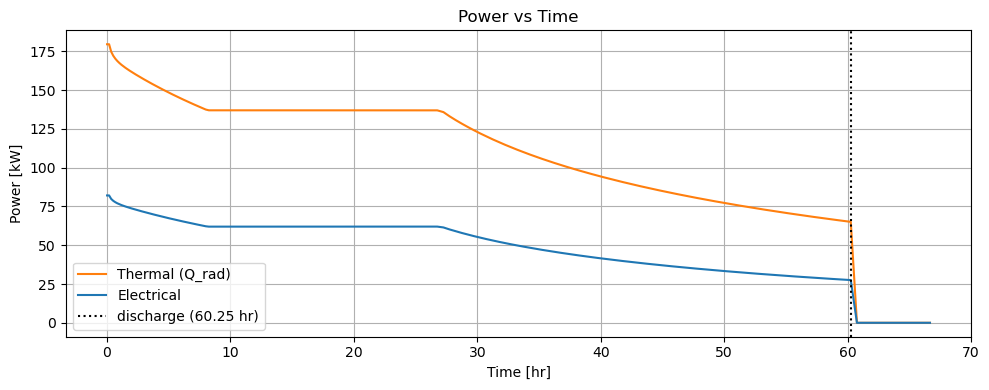

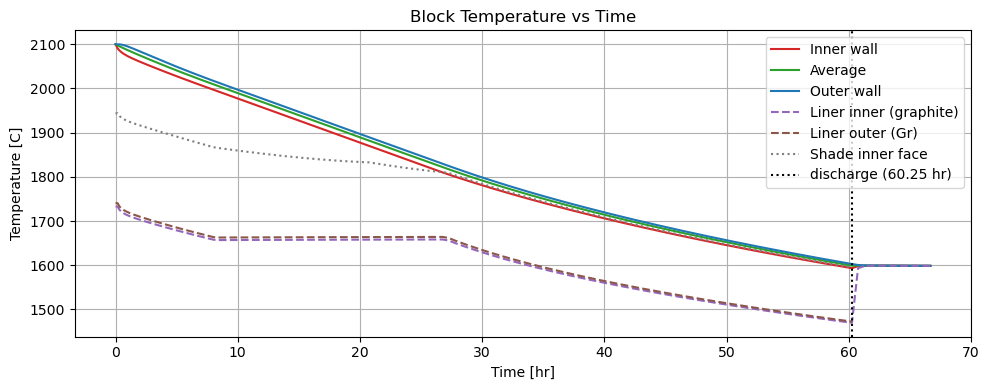

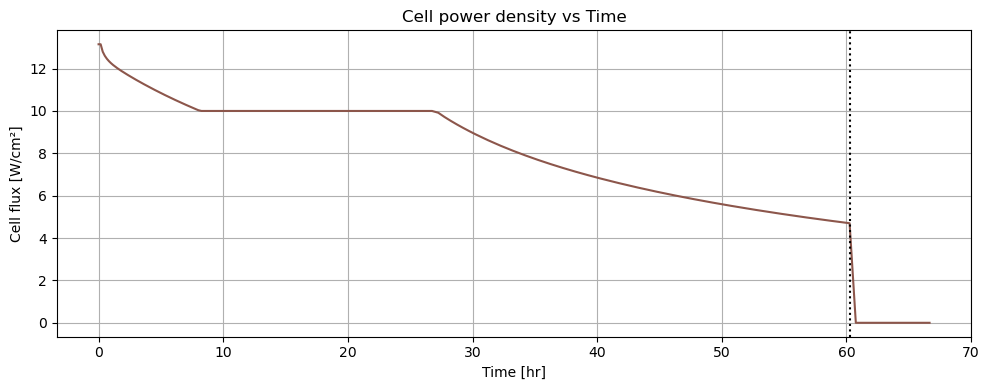

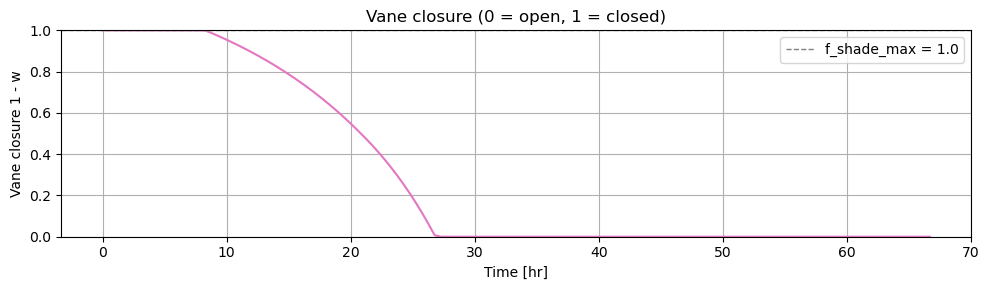

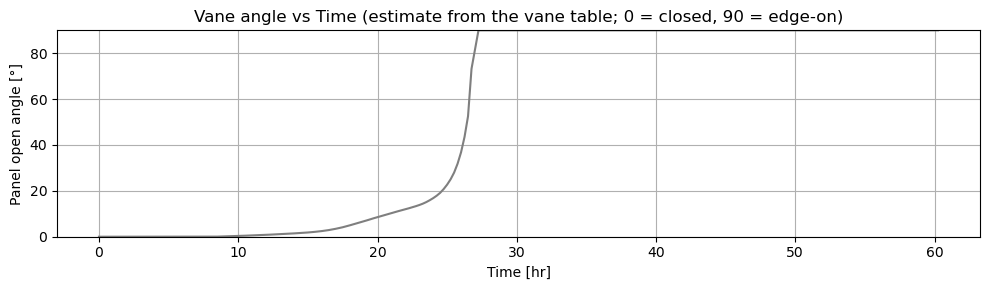

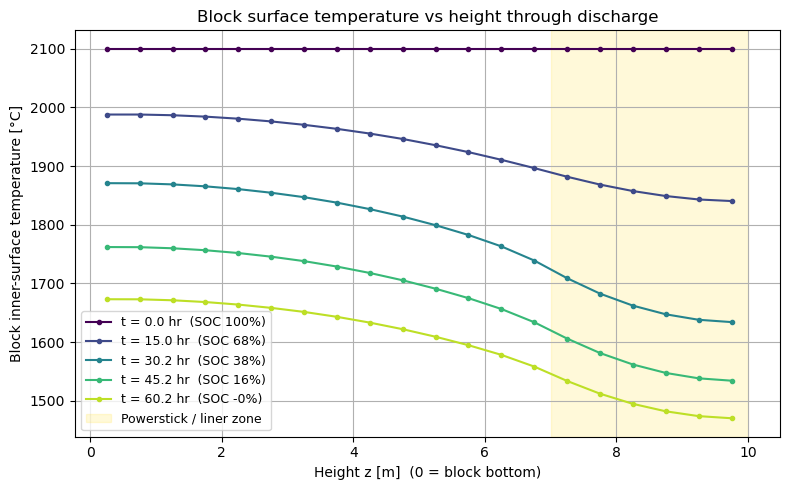

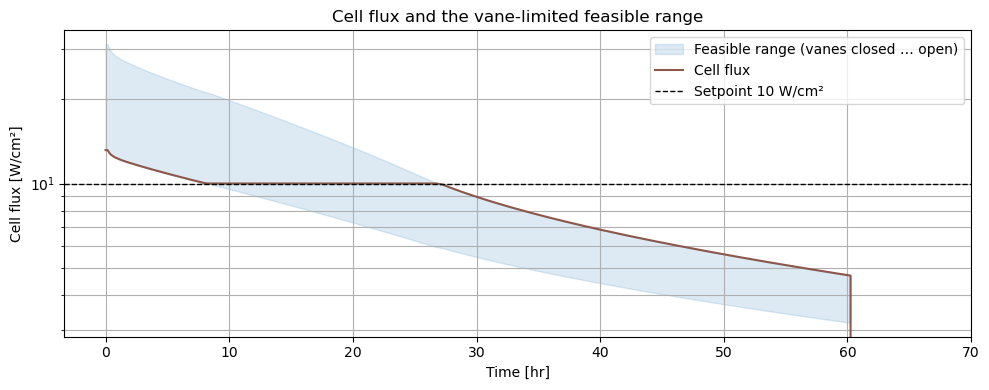

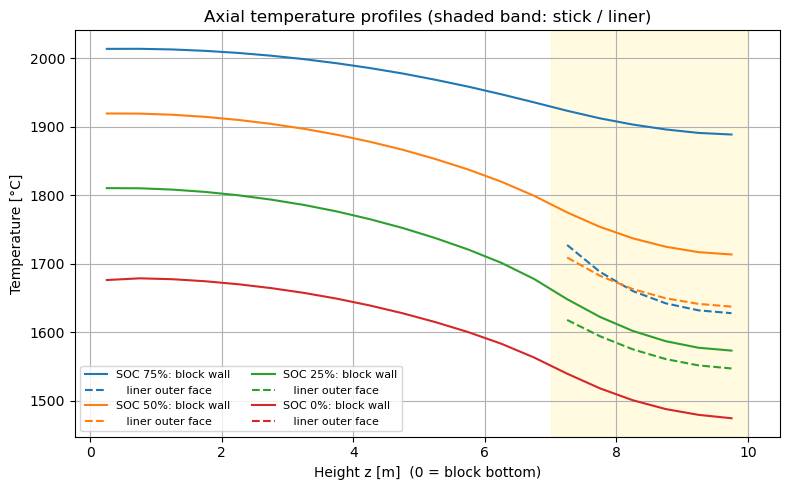

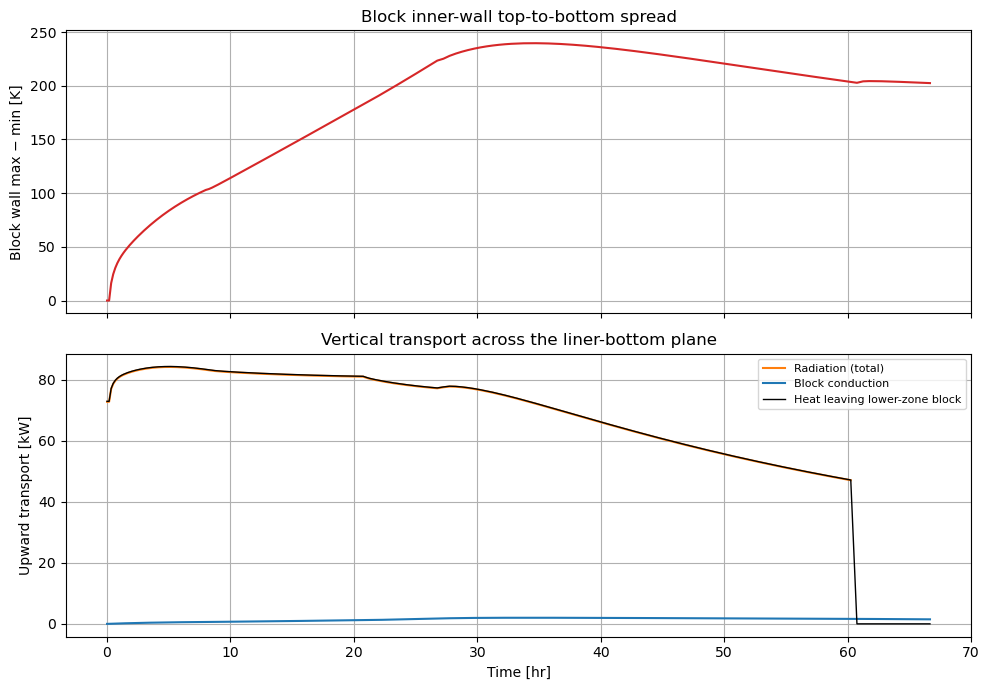

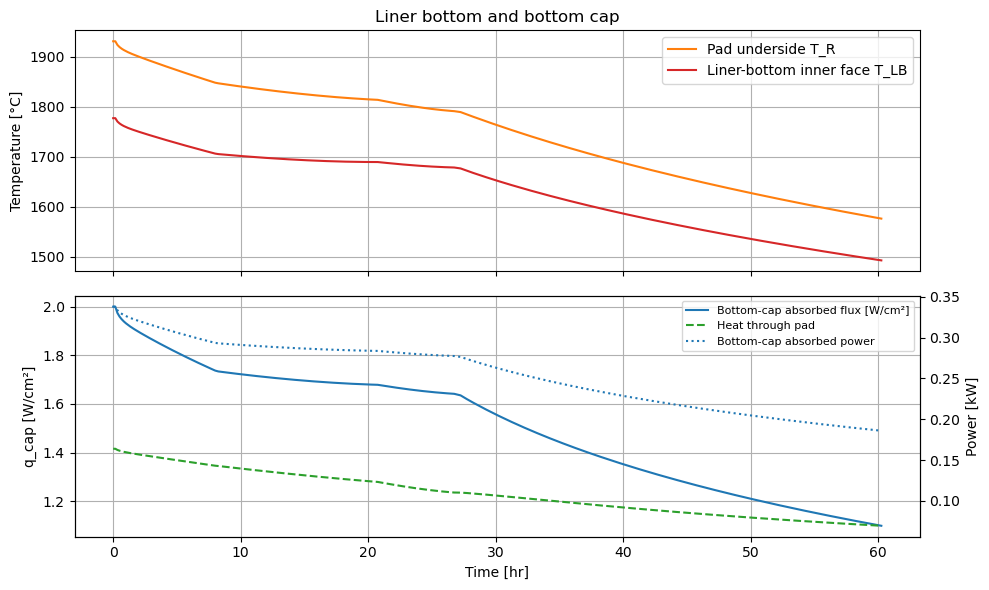

In [102]:
from scipy.integrate import cumulative_trapezoid

time_hr  = results['time'] / 3600
_t_dis_hr = results['t_ps_removed'] / 3600 if results.get('t_ps_removed') is not None else None
# -- State of charge analysis ------------------------------------------------
soc = (results['T_avg'] - T_min) / (T_max - T_min)

print()
print('T_inner - T_avg at SOC milestones:')
for target in [0.75, 0.50, 0.25, 0]:
    idx  = np.argmin(np.abs(soc - target))
    Ti   = results['T_inner'][idx]
    Ta   = results['T_avg'][idx]
    dT   = Ti - Ta
    t_hr = results['time'][idx] / 3600
    print(f'  SOC = {target*100:.0f}%  (t = {t_hr:.1f} hr)  '
          f'T_inner - T_avg = {dT:.1f} K  '
          f'(T_inner = {Ti-273.15:.0f} C, T_avg = {Ta-273.15:.0f} C)')
# -- Power vs time ------------------------------------------------------------
fig1, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(time_hr, results['Q_rad'] / 1e3, label='Thermal (Q_rad)', color='C1')
ax1.plot(time_hr, results['P_elec'] / 1e3, label='Electrical', color='C0')
ax1.set_xlabel('Time [hr]')
#ax1.set_xscale('log')
ax1.set_ylabel('Power [kW]')
ax1.set_title('Power vs Time')
ax1.legend()
ax1.grid(True)
if _t_dis_hr is not None:
    ax1.axvline(_t_dis_hr, color='k', ls=':', lw=1.5, label=f'discharge ({_t_dis_hr:.2f} hr)')
    ax1.legend()
fig1.tight_layout()

# -- Block temperature vs time ------------------------------------------------
fig2, ax2 = plt.subplots(figsize=(10, 4))
ax2.plot(time_hr, results['T_inner'] - 273.15, label='Inner wall', color='C3')
ax2.plot(time_hr, results['T_avg']   - 273.15, label='Average',    color='C2')
ax2.plot(time_hr, results['T_outer'] - 273.15, label='Outer wall', color='C0')
if results['T_liner'].any():
    ax2.plot(time_hr, results['T_liner'] - 273.15,
             label=f'Liner inner ({liner_material})', color='C4', linestyle='--')
if results.get('T_liner_out') is not None and np.any(np.isfinite(results['T_liner_out'])):
    ax2.plot(time_hr, results['T_liner_out'] - 273.15,
             label='Liner outer (Gr)', color='C5', linestyle='--')
if results.get('T_foil_inner') is not None and np.any(np.isfinite(results['T_foil_inner'])):
    ax2.plot(time_hr, results['T_foil_inner'] - 273.15,
             label='W foil', color='C6', linestyle='-.')
if results.get('T_sh_out') is not None and np.any(np.isfinite(results['T_sh_out'])):
    ax2.plot(time_hr, results['T_sh_out'] - 273.15,
             label='Shade inner face', color='C7', linestyle=':')
ax2.set_xlabel('Time [hr]')
#ax2.set_xscale('log')
ax2.set_ylabel('Temperature [C]')
ax2.set_title('Block Temperature vs Time')
ax2.legend()
ax2.grid(True)
if _t_dis_hr is not None:
    ax2.axvline(_t_dis_hr, color='k', ls=':', lw=1.5, label=f'discharge ({_t_dis_hr:.2f} hr)')
    ax2.legend()
fig2.tight_layout()

# -- Cumulative electrical / thermal energy -----------------------------------
cum_Q = cumulative_trapezoid(results['Q_rad'],  results['time'], initial=0)
cum_P = cumulative_trapezoid(results['P_elec'], results['time'], initial=0)
with np.errstate(divide='ignore', invalid='ignore'):
    cum_eff = np.where(cum_Q > 0, cum_P / cum_Q * 100, 0.0)


total_Q = cum_Q[-1]
total_P = cum_P[-1]
print(f"Total thermal energy absorbed:   {total_Q/3.6e9:.3f} MWhr")
print(f"Total electrical energy generated: {total_P/3.6e9:.3f} MWhr")
print(f"Overall efficiency:              {total_P/total_Q*100:.2f}%")
if _t_dis_hr is not None:
    print(f"Discharge time (T_avg \u2192 T_min):  {_t_dis_hr:.4f} hr  ({results['t_ps_removed']:.0f} s  = {_t_dis_hr*60:.1f} min)")
if results.get('dep_total_nm', 0) > 0:
    print(f"Integrated C deposition on PS:   {results['dep_C_nm']:.2f} nm")
    print(f"Integrated metal deposition:     {results['dep_metal_nm']:.4f} nm")
    print(f"Total deposition on PS:          {results['dep_total_nm']:.2f} nm")
    _t_sim       = results['time'][-1]           # one discharge [s]
    _cycle_time  = 2 * _t_sim                    # discharge + charge [s]
    _cycles_per_yr = 3.154e7 / _cycle_time
    for _yrs in (5, 30):
        _dep_nm = results['dep_total_nm'] * _cycles_per_yr * _yrs
        print(f"  → {_yrs:2d}-yr deposition ({_cycles_per_yr:.1f} cycles/yr):  {_dep_nm:.1f} nm  ({_dep_nm/1e3:.3f} µm)")

# -- Cell flux vs time ------------------------------------------------------
_cell_area_cm2 = 4 * side_len * L * (1 - f_bare) * f_active * 1e4  # cm²
fig3, ax3 = plt.subplots(figsize=(10, 4))
ax3.plot(time_hr, results['Q_cell'] / _cell_area_cm2, color='C5')
ax3.set_xlabel('Time [hr]')
#ax3.set_xscale('log')
ax3.set_ylabel('Cell flux [W/cm²]')
ax3.set_title('Cell power density vs Time')
ax3.grid(True)
if _t_dis_hr is not None:
    ax3.axvline(_t_dis_hr, color='k', ls=':', lw=1.5)
fig3.tight_layout()

# -- Shade fraction vs time (only when shade is active) -------------------
if shade_bool and results['f_shade'].max() > 0:
    fig4, ax4 = plt.subplots(figsize=(10, 3))
    ax4.plot(time_hr, results['f_shade'], color='C6')
    ax4.axhline(f_shade_max, color='gray', ls='--', lw=1, label=f'f_shade_max = {np.round(f_shade_max, 3)}')
    ax4.set_xlabel('Time [hr]')
    #ax4.set_xscale('log')
    ax4.set_ylabel('Vane closure 1 - w' if vane_model else 'Shade fraction  $f_{shade}$')
    ax4.set_title('Vane closure (0 = open, 1 = closed)' if vane_model else 'Shade area fraction vs Time')
    ax4.set_ylim(0, 1)
    ax4.legend()
    ax4.grid(True)
    fig4.tight_layout()

# -- Shade panel / vane angle vs time ------------------------------------
if shade_bool and results['f_shade'].max() > 0:
    if vane_model:
        # approximate: blend weight between the closed/open limits mapped to an angle
        # with the ray-traced vane table (thermal.correlations.VANE_GRID), ~1-3 deg
        theta_angle = results['vane_angle']
        _ttl = 'Vane angle vs Time (estimate from the vane table; 0 = closed, 90 = edge-on)'
    else:
        # Invert f_shade(theta) = f_shade_max*cos(theta) + f_shade_min*sin(theta)
        # via lookup table (function is monotonically decreasing for theta > ~1.6 deg)
        _theta_lut  = np.linspace(0, 90, 5000)
        _f_lut      = (f_shade_max * np.cos(np.radians(_theta_lut))
                       + f_shade_min * np.sin(np.radians(_theta_lut)))
        theta_angle = np.interp(results['f_shade'], _f_lut[::-1], _theta_lut[::-1])
        _ttl = 'Shade panel open angle vs Time'
    fig5, ax5 = plt.subplots(figsize=(10, 3))
    ax5.plot(time_hr, theta_angle, color='C7')
    ax5.set_xlabel('Time [hr]')
    ax5.set_ylabel('Panel open angle [°]')
    ax5.set_title(_ttl)
    ax5.set_ylim(0, 90)
    ax5.grid(True)
    fig5.tight_layout()

# -- Block inner-surface temperature vs height at 5 times through discharge --
_snap_t   = results['snap_times']
_snaps    = results['temp_snapshots']                 # (n_snap, n_ax, n_rad)
_t_end    = results['t_ps_removed'] if results.get('t_ps_removed') is not None else results['time'][-1]
_dz_blk   = storage.axial_dz() if hasattr(storage, 'axial_dz') else np.full(_snaps.shape[1], L / _snaps.shape[1])
_z_edges  = np.concatenate([[0.0], np.cumsum(_dz_blk)])
_z_c      = 0.5 * (_z_edges[:-1] + _z_edges[1:])      # ring centres, z = 0 at block bottom
fig6, ax6 = plt.subplots(figsize=(8, 5))
_cols6 = plt.cm.viridis(np.linspace(0, 0.9, 5))
for _k, _t_target in enumerate(np.linspace(0.0, _t_end, 5)):
    _i = int(np.argmin(np.abs(_snap_t - _t_target)))
    _Ts = _snaps[_i][:, 0]                            # inner (radiating) surface ring
    _soc_i = (_snaps[_i].mean() - T_min) / (T_max - T_min)
    ax6.plot(_z_c, _Ts - 273.15, 'o-', ms=3, color=_cols6[_k],
             label=f't = {_snap_t[_i]/3600:.1f} hr  (SOC {_soc_i*100:.0f}%)')
if _z_edges[-1] > L + 1e-9:                           # block taller than powerstick: mark active zone
    ax6.axvspan(_z_edges[-1] - L, _z_edges[-1], color='gold', alpha=0.15, label='Powerstick / liner zone')
ax6.set_xlabel('Height z [m]  (0 = block bottom)')
ax6.set_ylabel('Block inner-surface temperature [°C]')
ax6.set_title('Block surface temperature vs height through discharge')
ax6.grid(True)
ax6.legend(fontsize=9)
fig6.tight_layout()

# =============================================================================
# Decoupled block height / axial model outputs (brief §5). Only drawn when the
# run used the axial model (radiation.axial: true).
# =============================================================================
_ax_on   = np.any(np.isfinite(results.get('Q_rad_low', [np.nan]))) or np.any(np.isfinite(results.get('Q_cell_min', [np.nan])))
_n_low   = getattr(getattr(sim, 'axial_model', None), 'n_low', 0)
_on      = results['ps_active'] | (results['time'] == (results['t_ps_removed'] or -1))
_dt      = np.diff(results['time'])

# -- Feasible cell-flux range (vane limits) and spread ------------------------
if np.any(np.isfinite(results['Q_cell_min'])):
    fig7, ax7 = plt.subplots(figsize=(10, 4))
    ax7.fill_between(time_hr, results['Q_cell_min'] / _cell_area_cm2, results['Q_cell_max'] / _cell_area_cm2,
                     color='C0', alpha=0.15, label='Feasible range (vanes closed … open)')
    ax7.plot(time_hr, results['Q_cell'] / _cell_area_cm2, color='C5', label='Cell flux')
    ax7.axhline(avg_flux, color='k', ls='--', lw=1, label=f'Setpoint {avg_flux} W/cm²')
    _held = np.abs(results['Q_cell'] / _cell_area_cm2 - avg_flux) < 1e-3 * avg_flux
    print(f"Setpoint held for {np.sum(_dt[_held[1:]])/3600:.1f} h of {results['time'][-1]/3600:.1f} h; "
          f"over setpoint (vanes fully closed) for {np.sum(_dt[(results['Q_cell'][1:] / _cell_area_cm2 > avg_flux * 1.001)])/3600:.1f} h")
    ax7.set_yscale('log')
    ax7.set_xlabel('Time [hr]'); ax7.set_ylabel('Cell flux [W/cm²]')
    ax7.set_title('Cell flux and the vane-limited feasible range')
    ax7.grid(True, which='both'); ax7.legend(); fig7.tight_layout()

if _ax_on and _n_low:
    # -- Axial profiles at SOC 75/50/25/0 % -----------------------------------
    _snaps, _snap_t = results['temp_snapshots'], results['snap_times']
    _soc_s  = (_snaps.mean(axis=(1, 2)) - T_min) / (T_max - T_min)
    _ea     = _z_edges[-1] - L + np.linspace(0, L, results['liner_out_snaps'].shape[1] + 1)
    _za     = 0.5 * (_ea[1:] + _ea[:-1])
    fig8, ax8 = plt.subplots(figsize=(8, 5))
    for _k, _soc_t in enumerate((0.75, 0.50, 0.25, 0.0)):
        _i = int(np.argmin(np.abs(_soc_s - _soc_t)))
        ax8.plot(_z_c, _snaps[_i][:, 0] - 273.15, '-', color=f'C{_k}', label=f'SOC {max(_soc_s[_i], 0)*100:.0f}%: block wall')
        ax8.plot(_za, results['liner_out_snaps'][_i] - 273.15, '--', color=f'C{_k}', label='   liner outer face')
    ax8.axvspan(_z_edges[-1] - L, _z_edges[-1], color='gold', alpha=0.12)
    ax8.set_xlabel('Height z [m]  (0 = block bottom)'); ax8.set_ylabel('Temperature [°C]')
    ax8.set_title('Axial temperature profiles (shaded band: stick / liner)')
    ax8.grid(True); ax8.legend(fontsize=8, ncol=2); fig8.tight_layout()

    # -- Top-to-bottom spread and vertical transport across the liner-bottom plane
    fig9, (ax9a, ax9b) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
    ax9a.plot(time_hr, results['T_wall_spread'], color='C3')
    ax9a.set_ylabel('Block wall max − min [K]'); ax9a.set_title('Block inner-wall top-to-bottom spread')
    ax9a.grid(True)
    ax9b.plot(time_hr, results['Q_vert_rad'] / 1e3, label='Radiation (total)', color='C1')
    for _kk, _c in (('outer', 'C2'), ('inner', 'C4'), ('through', 'C6')):
        if np.any(np.isfinite(results[f'Q_vert_rad_{_kk}'])):
            ax9b.plot(time_hr, results[f'Q_vert_rad_{_kk}'] / 1e3, ls='--', color=_c, label=f'  radiation, {_kk}')
    ax9b.plot(time_hr, results['Q_vert_cond'] / 1e3, label='Block conduction', color='C0')
    ax9b.plot(time_hr, results['Q_rad_low'] / 1e3, label='Heat leaving lower-zone block', color='k', lw=1)
    ax9b.set_xlabel('Time [hr]'); ax9b.set_ylabel('Upward transport [kW]')
    ax9b.set_title('Vertical transport across the liner-bottom plane')
    ax9b.grid(True); ax9b.legend(fontsize=8); fig9.tight_layout()

    # -- Energy split: lower zone vs active zone --------------------------------
    _E_tot = np.nansum(results['Q_rad'][1:] * _dt)
    _E_low = np.nansum(results['Q_rad_low'][1:] * _dt)
    print(f"Energy delivered from the lower zone: {_E_low/3.6e6:.0f} kWh ({_E_low/_E_tot*100:.1f}%), "
          f"active zone: {(_E_tot-_E_low)/3.6e6:.0f} kWh ({(1-_E_low/_E_tot)*100:.1f}%)")

# -- Liner bottom / bottom cap (liner_bottom.enabled) -------------------------
if np.any(np.isfinite(results['q_cap'])):
    fig10, (ax10a, ax10b) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
    ax10a.plot(time_hr, results['T_R'] - 273.15, label='Pad underside T_R', color='C1')
    ax10a.plot(time_hr, results['T_LB'] - 273.15, label='Liner-bottom inner face T_LB', color='C3')
    ax10a.set_ylabel('Temperature [°C]'); ax10a.grid(True); ax10a.legend()
    ax10a.set_title('Liner bottom and bottom cap')
    ax10b.plot(time_hr, results['q_cap'], label='Bottom-cap absorbed flux [W/cm²]', color='C0')
    ax10b.set_ylabel('q_cap [W/cm²]'); ax10b.set_xlabel('Time [hr]'); ax10b.grid(True)
    _axb = ax10b.twinx()
    _axb.plot(time_hr, results['Q_pad'] / 1e3, color='C2', ls='--', label='Heat through pad')
    _axb.plot(time_hr, results['Q_cap'] / 1e3, color='C0', ls=':', label='Bottom-cap absorbed power')
    _axb.set_ylabel('Power [kW]')
    _h1, _l1 = ax10b.get_legend_handles_labels(); _h2, _l2 = _axb.get_legend_handles_labels()
    ax10b.legend(_h1 + _h2, _l1 + _l2, fontsize=8)
    fig10.tight_layout()
    _ok = np.isfinite(results['Q_cap'][1:])
    print(f"Bottom cap: avg {np.nanmean(results['q_cap']):.2f}, peak {np.nanmax(results['q_cap']):.2f} W/cm², "
          f"energy {np.sum((results['Q_cap'][1:] * _dt)[_ok])/3.6e6:.1f} kWh per discharge; "
          f"T_LB {np.nanmin(results['T_LB'])-273.15:.0f}–{np.nanmax(results['T_LB'])-273.15:.0f} °C")

plt.show()


c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:514: RuntimeWarning: Mean of empty slice
  T_foil_inner_arr  = [np.nanmean(_st0['T_foil_inner'])]
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:541: RuntimeWarning: Mean of empty slice
  np.nanmean(_st0['T_foil_inner']))
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:615: RuntimeWarning: Mean of empty slice
  T_foil_inner_arr.append(np.nanmean(_st['T_foil_inner']))
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:630: RuntimeWarning: Mean of empty slice
  np.nanmean(_st['T_foil_inner']))


[discharge] T_avg=1872 K reached cutoff 1873 K at t=60.2500 hr (216900.0 s) — powerstick removed, conduction-only phase begins.
pass 1: T_min 1873.0 K, volume x1.0000 (r_out 0.9923 m) -> shades open at 2092.2 K (+219.2), 27.04 h (-45.92%)


c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:614: RuntimeWarning: Mean of empty slice
  T_liner_out_arr.append(np.nanmean(_st['T_liner_out']))
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:616: RuntimeWarning: Mean of empty slice
  T_sh_in_arr.append(np.nanmean(_st['T_sh_in']))
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:617: RuntimeWarning: Mean of empty slice
  T_sh_out_arr.append(np.nanmean(_st['T_sh_out']))
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:514: RuntimeWarning: Mean of empty slice
  T_foil_inner_arr  = [np.nanmean(_st0['T_foil_inner'])]
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:541: RuntimeWarning: Mean of empty slice
  np.nanmean(_st0['T_foil_inner']))
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:615: RuntimeWarning: Mean of empty slice
  T_foil_inner_arr.append(np.nanmean(_st['T_foil_inner']))
c:\Users\NateColgan\Documents\thermal model

[discharge] T_avg=2091 K reached cutoff 2092 K at t=49.9167 hr (179700.0 s) — powerstick removed, conduction-only phase begins.
pass 2: T_min 2092.2 K, volume x1.0513 (r_out 1.2040 m) -> shades open at 2099.8 K (+7.5), 48.18 h (-3.65%)


c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:614: RuntimeWarning: Mean of empty slice
  T_liner_out_arr.append(np.nanmean(_st['T_liner_out']))
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:616: RuntimeWarning: Mean of empty slice
  T_sh_in_arr.append(np.nanmean(_st['T_sh_in']))
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:617: RuntimeWarning: Mean of empty slice
  T_sh_out_arr.append(np.nanmean(_st['T_sh_out']))
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:514: RuntimeWarning: Mean of empty slice
  T_foil_inner_arr  = [np.nanmean(_st0['T_foil_inner'])]
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:541: RuntimeWarning: Mean of empty slice
  np.nanmean(_st0['T_foil_inner']))
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:615: RuntimeWarning: Mean of empty slice
  T_foil_inner_arr.append(np.nanmean(_st['T_foil_inner']))
c:\Users\NateColgan\Documents\thermal model

[discharge] T_avg=2097 K reached cutoff 2100 K at t=50.4167 hr (181500.0 s) — powerstick removed, conduction-only phase begins.
pass 3: T_min 2099.8 K, volume x1.0622 (r_out 1.2198 m) -> shades open at 2100.0 K (+0.2), 49.92 h (-0.17%)

Converged after 3 passes (1.1 min)
T_min  1873.0 -> 2099.8 K   (1600 -> 1827 C)
swing  500.0 -> 273.2 K   (T_max 2373.0 K fixed)
block  r_out 0.9923 -> 1.2198 m, volume 17.206 -> 33.018 m3 (volume_factor 1.0622)
shades fully open at 2100.0 K, 49.92 h (target 50 h)

YAML cell, storage section:
  T_min: 2099.8
  block_temp_range: 273.2
  volume_factor: 1.0622


c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:614: RuntimeWarning: Mean of empty slice
  T_liner_out_arr.append(np.nanmean(_st['T_liner_out']))
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:616: RuntimeWarning: Mean of empty slice
  T_sh_in_arr.append(np.nanmean(_st['T_sh_in']))
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:617: RuntimeWarning: Mean of empty slice
  T_sh_out_arr.append(np.nanmean(_st['T_sh_out']))


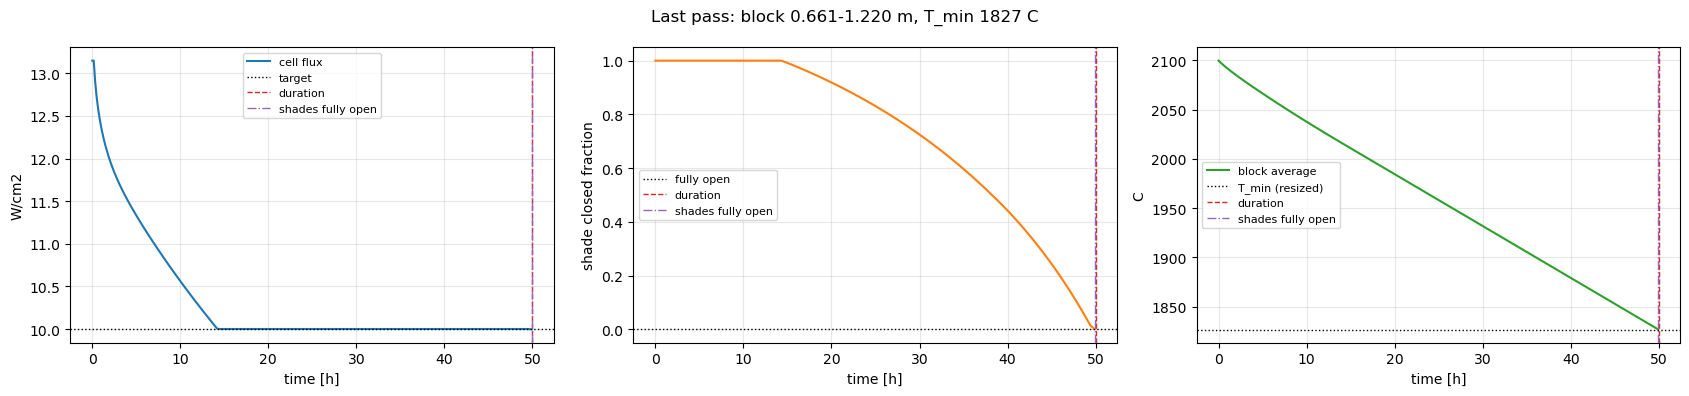


pass  T_min[K]  swing[K]  vol_factor  r_out[m]  t_open[h]  T_open[K]  opening
   1    1873.0     500.0      1.0000    0.9923      27.04     2092.2  seen
   2    2092.2     280.8      1.0513    1.2040      48.18     2099.8  seen
   3    2099.8     273.2      1.0622    1.2198      49.92     2100.0  seen


In [103]:
# -- Resize so the shades just reach fully open at the end of the discharge --------
# For the design in the YAML: run the discharge, find the block temperature at which the
# shades are fully open, set T_min to it and rescale the block volume so that point falls
# at duration_hr; iterate until both hold (T_max fixed). Block temperature = the
# volume-weighted block average (as the discharge cutoff). Each pass is the same discharge run as the cell above
# (~2 min); if the shades are still regulating when the stick comes out at T_min, the
# opening is extrapolated from shade position vs block temperature (shrinks to zero as it
# converges).
# Self-contained (loads tinless_model_input.yaml). The result is the storage.T_min,
# storage.block_temp_range and storage.volume_factor to put in the YAML cell.
import time as _time
import yaml as _yaml
import numpy as np
import matplotlib.pyplot as plt
from thermal.build import build_tinless
import importlib as _il
import thermal.sizing as _sz
_il.reload(_sz)                     # pick up edits to thermal/sizing.py
from thermal.sizing import shade_open_resize, cell_flux

SO_TOL_T = 2.0       # K   |T at shade opening - T_min|
SO_TOL_t = 0.005     # -   |t at shade opening / duration - 1|
SO_MAX_IT = 8

with open('tinless_model_input.yaml') as _f:
    _cfg_so = _yaml.safe_load(_f)
_s0 = _cfg_so['storage']
_m0 = build_tinless(_cfg_so, geometry_only=True)

_t0 = _time.perf_counter()
so = shade_open_resize(_cfg_so, tol_T=SO_TOL_T, tol_t=SO_TOL_t, max_iter=SO_MAX_IT)
print(f"\n{'Converged' if so.converged else 'NOT converged'} after {len(so.history)} passes "
      f"({(_time.perf_counter() - _t0) / 60:.1f} min)")
print(f"T_min  {_s0['T_min']:.1f} -> {so.T_min:.1f} K   ({_s0['T_min'] - 273.15:.0f} -> {so.T_min - 273.15:.0f} C)")
print(f"swing  {_s0['block_temp_range']:.1f} -> {so.swing:.1f} K   (T_max {so.T_max:.1f} K fixed)")
print(f"block  r_out {_m0.r_out:.4f} -> {so.r_out:.4f} m, volume {_m0.V_block:.3f} -> {so.m.V_block:.3f} m3 "
      f"(volume_factor {so.volume_factor:.4f})")
print(f"shades fully open at {so.T_open:.1f} K, {so.t_open_hr:.2f} h (target {_s0['duration_hr']} h)")
print("\nYAML cell, storage section:")
print(f"  T_min: {so.T_min:.1f}\n  block_temp_range: {so.swing:.1f}\n  volume_factor: {so.volume_factor:.4f}")

# Last pass
_m, _r = so.m, so.r
_t = _r['time'] / 3600
_on = np.asarray(_r['ps_active'], bool)
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].plot(_t[_on], cell_flux(_m, _r)[_on], label='cell flux')
ax[0].axhline(_m.avg_flux, c='k', ls=':', lw=1, label='target')
ax[0].set_ylabel('W/cm2')
ax[1].plot(_t[_on], np.asarray(_r['f_shade'])[_on], c='C1')
ax[1].axhline(_m.f_shade_min, c='k', ls=':', lw=1, label='fully open')
ax[1].set_ylabel('shade closed fraction')
ax[2].plot(_t[_on], np.asarray(_r['T_avg'])[_on] - 273.15, c='C2', label='block average')
ax[2].axhline(so.T_min - 273.15, c='k', ls=':', lw=1, label='T_min (resized)')
ax[2].set_ylabel('C')
for a in ax:
    a.axvline(_s0['duration_hr'], c='C3', ls='--', lw=1, label='duration')
    a.axvline(so.t_open_hr, c='C4', ls='-.', lw=1, label='shades fully open')
    a.set_xlabel('time [h]'); a.grid(alpha=.3); a.legend(fontsize=8)
fig.suptitle(f"Last pass: block {_m.r_in:.3f}-{_m.r_out:.3f} m, T_min {_m.T_min - 273.15:.0f} C")
plt.tight_layout(); plt.show()

print("\npass  T_min[K]  swing[K]  vol_factor  r_out[m]  t_open[h]  T_open[K]  opening")
for h in so.history:
    print(f"{h['it']:4d}  {h['T_min']:8.1f}  {h['swing']:8.1f}  {h['volume_factor']:10.4f}  {h['r_out']:8.4f}  "
          f"{h['t_open_hr']:9.2f}  {h['T_open']:9.1f}  {'seen' if h.get('seen') else 'extrapolated' if h.get('seen') is False else '-'}")


discharge ...


c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:514: RuntimeWarning: Mean of empty slice
  T_foil_inner_arr  = [np.nanmean(_st0['T_foil_inner'])]
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:541: RuntimeWarning: Mean of empty slice
  np.nanmean(_st0['T_foil_inner']))
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:615: RuntimeWarning: Mean of empty slice
  T_foil_inner_arr.append(np.nanmean(_st['T_foil_inner']))
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:630: RuntimeWarning: Mean of empty slice
  np.nanmean(_st['T_foil_inner']))


[discharge] T_avg=1872 K reached cutoff 1873 K at t=60.2500 hr (216900.0 s) — powerstick removed, conduction-only phase begins.
charge ...


c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:614: RuntimeWarning: Mean of empty slice
  T_liner_out_arr.append(np.nanmean(_st['T_liner_out']))
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:616: RuntimeWarning: Mean of empty slice
  T_sh_in_arr.append(np.nanmean(_st['T_sh_in']))
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:617: RuntimeWarning: Mean of empty slice
  T_sh_out_arr.append(np.nanmean(_st['T_sh_out']))


Block fully charged: T_avg=2376.9 K >= 2373.0 K at t=9.33 hr
tank ...
Plant: 509 sticks + 509 heaters; block 1600-2100 C; cycle 133.3 h = charge 9.3 + hold 63.8 + discharge 60.2 h
Round trip: 38.6% net (40.2% before fans);  AC in 3,755 MWh, net AC out 1,448 MWh per cycle

                                                                MWh/cycle  kWh/stick % of AC in
power electronics       heater supply (1 - eta_in)                   75.1        148       2.0%
insulation: charge      roof + floor (cell losses)                   10.0         20       0.3%
                        side + edges                                  4.9         10       0.1%
insulation: hold        side                                         41.4         81       1.1%
                        edges                                         4.4          9       0.1%
                        roof                                         33.8         66       0.9%
                        floor                          

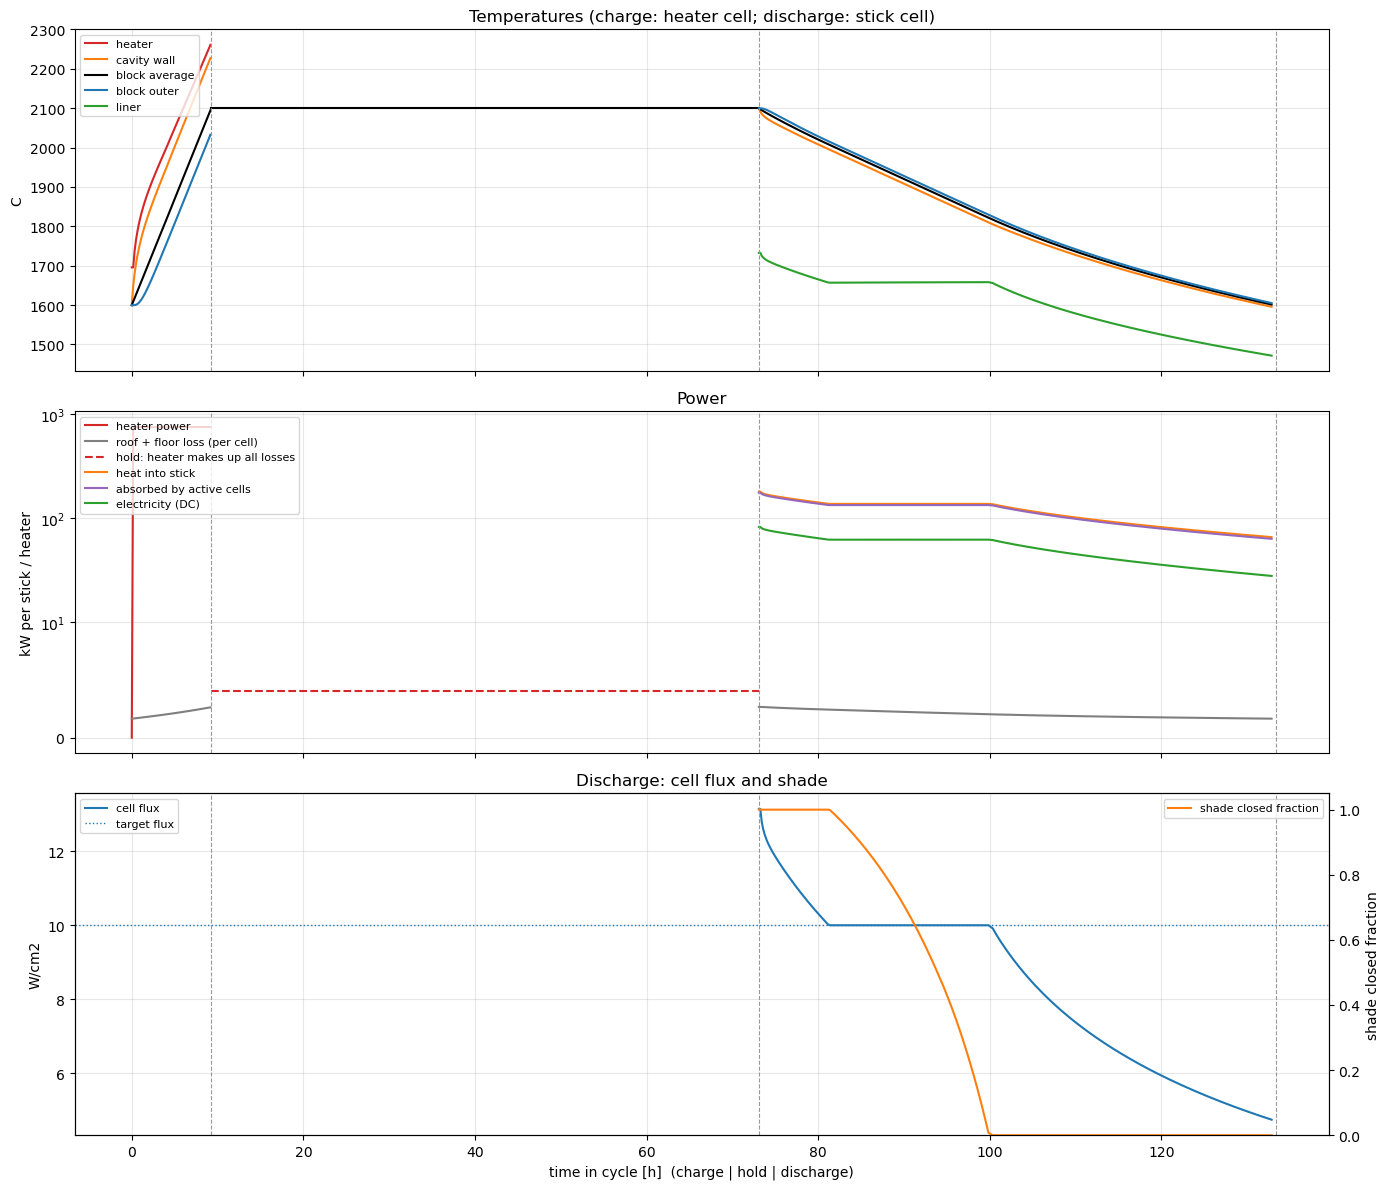

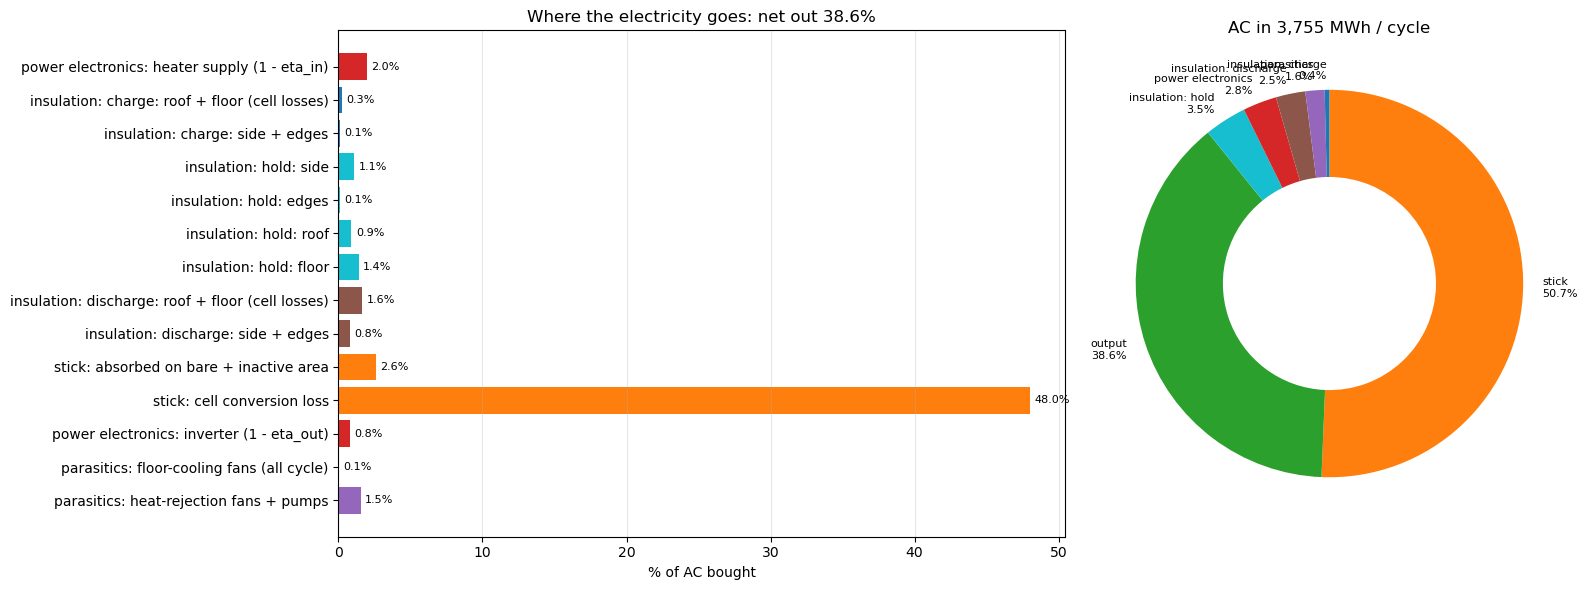

In [104]:
# -- Full cycle: charge -> hold -> discharge, round-trip efficiency and loss breakdown --
# The YAML design as it stands (no block resizing, heater.area_ratio as given). Charge: heater
# cell from T_min until the block average reaches T_max. Hold: heaters keep the block at
# T_max for 8760 / cycles_per_year - charge - discharge. Discharge: the same run as the main
# cell above. Plant: tank sized as the optimizer does, inverters, floor-cooling fans (all
# cycle) and heat-rejection fans. Efficiencies / cycles / fan factor: thermal.optimize.OPT_DEFAULTS.
# Self-contained (loads tinless_model_input.yaml). Model: thermal/cycle.py.
import time as _time
import yaml as _yaml
import numpy as np
import matplotlib.pyplot as plt
import importlib as _il
import thermal.sizing as _sz, thermal.optimize as _op, thermal.cycle as _cyc
for _mod in (_sz, _op, _cyc):           # pick up edits to the modules
    _il.reload(_mod)
from thermal.cycle import run_cycle, J_MWh
from thermal.sizing import cell_flux

CYCLE_OPT = {}            # e.g. {'economics': {'cycles_per_year': 65.7, 'eta_in': 0.98, 'eta_out': 0.98}}
CYCLE_DEGRADATION = None  # e.g. {'cell': 0.05, 'bare': 0.005} for part-worn cells; None = clean

with open('tinless_model_input.yaml') as _f:
    _cfg_cy = _yaml.safe_load(_f)
_t0 = _time.perf_counter()
cy = run_cycle(_cfg_cy, opt=CYCLE_OPT, degradation=CYCLE_DEGRADATION)
print(f"\n({(_time.perf_counter() - _t0) / 60:.1f} min)")

# ---- time series, one stick + one heater cell (plant = x N) -------------------------
_rc, _rd, _m = cy.r_chg, cy.r_dis, cy.m
_tc = np.asarray(_rc['time']) / 3600
_kc = _tc <= cy.t_charge_hr + 1e-9
_t1 = cy.t_charge_hr + cy.t_hold_hr                     # discharge starts here
_on = np.asarray(_rd['ps_active'], bool)
_td = np.asarray(_rd['time'])[_on] / 3600 + _t1
_t_end = _t1 + cy.t_discharge_hr
_C = lambda T: np.asarray(T, float) - 273.15

fig, ax = plt.subplots(3, 1, figsize=(14, 12), sharex=True)
a = ax[0]
a.plot(_tc[_kc], _C(_rc['T_heater'])[_kc], c='C3', label='heater')
a.plot(_tc[_kc], _C(_rc['T_inner'])[_kc], c='C1', label='cavity wall')
a.plot(_tc[_kc], _C(_rc['T_avg'])[_kc], c='k', label='block average')
a.plot(_tc[_kc], _C(_rc['T_outer'])[_kc], c='C0', label='block outer')
a.plot([cy.t_charge_hr, _t1], [cy.T_max_C] * 2, c='k')
a.plot(_td, _C(_rd['T_inner'])[_on], c='C1')
a.plot(_td, _C(_rd['T_avg'])[_on], c='k')
a.plot(_td, _C(_rd['T_outer'])[_on], c='C0')
if _m.liner_bool:
    a.plot(_td, _C(_rd['T_liner'])[_on], c='C2', label='liner')
a.set_ylabel('C'); a.set_title('Temperatures (charge: heater cell; discharge: stick cell)')

a = ax[1]
a.plot(_tc[_kc], np.asarray(_rc['Q_heater'])[_kc] / 1e3, c='C3', label='heater power')
a.plot(_tc[_kc], np.asarray(_rc['Q_sink'])[_kc] / 1e3, c='C7', label='roof + floor loss (per cell)')
a.plot([cy.t_charge_hr, _t1], [cy.hold_loss_W / cy.N / 1e3] * 2, c='C3', ls='--', label='hold: heater makes up all losses')
a.plot(_td, np.asarray(_rd['Q_rad'])[_on] / 1e3, c='C1', label='heat into stick')
a.plot(_td, np.asarray(_rd['Q_cell'])[_on] / 1e3, c='C4', label='absorbed by active cells')
a.plot(_td, np.asarray(_rd['P_elec'])[_on] / 1e3, c='C2', label='electricity (DC)')
a.plot(_td, np.asarray(_rd['Q_sink'])[_on] / 1e3, c='C7')
a.set_ylabel('kW per stick / heater'); a.set_yscale('symlog', linthresh=10); a.set_title('Power')

a = ax[2]
a.plot(_td, cell_flux(_m, _rd)[_on], c='C0', label='cell flux')
a.axhline(_m.avg_flux, c='C0', ls=':', lw=1, label='target flux')
a.set_ylabel('W/cm2'); a.set_title('Discharge: cell flux and shade')
a2 = a.twinx()
a2.plot(_td, np.asarray(_rd['f_shade'])[_on], c='C1', label='shade closed fraction')
a2.set_ylabel('shade closed fraction'); a2.set_ylim(0, 1.05)
a2.legend(loc='upper right', fontsize=8)
for a in ax:
    for x in (cy.t_charge_hr, _t1, _t_end):
        a.axvline(x, c='0.6', lw=.8, ls='--')
    a.grid(alpha=.3); a.legend(loc='upper left', fontsize=8)
ax[-1].set_xlabel('time in cycle [h]  (charge | hold | discharge)')
plt.tight_layout(); plt.show()

# ---- loss breakdown --------------------------------------------------------------
_rows = [r for r in cy.ledger if r[0] != 'output']
_cols = {'power electronics': 'C3', 'insulation: charge': 'C0', 'insulation: hold': 'C9',
         'insulation: discharge': 'C5', 'stick': 'C1', 'parasitics': 'C4', 'residual': '0.6'}
fig, ax = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [3, 2]})
_lab = [f"{g}: {l}" for g, l, _ in _rows]
_pct = np.array([v for _, _, v in _rows]) / cy.AC_in * 100
ax[0].barh(_lab, _pct, color=[_cols.get(g, 'k') for g, _, _ in _rows])
for i, p in enumerate(_pct):
    ax[0].text(max(p, 0) + 0.3, i, f"{p:.1f}%", va='center', fontsize=8)
ax[0].invert_yaxis(); ax[0].set_xlabel('% of AC bought'); ax[0].grid(alpha=.3, axis='x')
ax[0].set_title(f"Where the electricity goes: net out {cy.RTE*100:.1f}%")
_g = sorted([(g, v) for g, v in cy.groups.items()], key=lambda kv: -kv[1])
ax[1].pie([max(v, 0) for _, v in _g], labels=[f"{g}\n{v/cy.AC_in*100:.1f}%" for g, v in _g],
          colors=[_cols.get(g, 'C2') for g, _ in _g], startangle=90, counterclock=False,
          wedgeprops=dict(width=.45), textprops=dict(fontsize=8))
ax[1].set_title(f"AC in {cy.AC_in*J_MWh:,.0f} MWh / cycle")
plt.tight_layout(); plt.show()


In [72]:
# -- Heating simulation (single heater) -----------------------------------------
# thermal.build.build_heater: the heater cell holds the same graphite as the stick cell
# (volume, block height, axial mesh, radial rings) around the heater cavity
#   r_hcav = heater.area_ratio * r_heater_eff,  r_heater_eff = 2 side_len / pi
# Heater spans the full block height; outer wall adiabatic (symmetry line to the
# stick). Block starts at T_min and stops at T_min + block_temp_range (volume-weighted
# average). Roof + floor losses on the top / bottom rings when tank.block_axial_losses.
from thermal.build import build_tinless as _bt, build_heater as _bh, load_config as _lc
from thermal.tank import cell_loss_sink as _cls

_cfg  = _lc('tinless_model_input.yaml')
_m    = _bt(_cfg, geometry_only=True)
_hm   = _bh(_m)
_sink = (_cls(_m, _cfg['tank']).for_storage(_hm.storage)
         if _cfg.get('tank') and _cfg['tank'].get('block_axial_losses', True) else None)
_charge_limit_hr = 200          # give up if not charged by then

_T_min, _T_block_max = _hm.T_min, _hm.T_max
_he_P_max = _hm.heater.max_power
_E_block = storage_rho(_T_block_max) * storage_cp(_T_block_max) * _hm.V * (_T_block_max - _T_min)
print(f'Heater cell: heater r {_hm.r_heater:.3f} m in cavity r {_hm.r_in:.3f} m (area_ratio {_hm.area_ratio}), '
      f'graphite to r_out {_hm.r_out:.3f} m, H {_hm.H} m, V {_hm.V:.2f} m3 (= stick cell)')
print(f'Charge {_T_min:.0f} -> {_T_block_max:.0f} K: {_E_block/3.6e6:,.0f} kWh_th; heater max '
      f'{_hm.heater.max_temperature:.0f} K / {_he_P_max/1e3:.0f} kW -> power-limited minimum '
      f'{_E_block/_he_P_max/3600:.1f} h')
if _hm.heater.max_temperature <= _T_block_max:
    print('WARNING: heater max temperature <= block T_max: the block cannot be fully charged')

_heat_res = _hm.sim.run_heating_simulation(
    _hm.heater, end_time=_charge_limit_hr * 3600, snap_every=3600,
    print_interval=int(6 * 3600 / _hm.run_kwargs['dt']), Q_sink_fn=_sink, **_hm.run_kwargs)

# -- Summary -------------------------------------------------------------------
_t_hr = _heat_res['time'] / 3600
_E_in = np.trapz(_heat_res['Q_heater'], _heat_res['time'])
_E_s  = np.trapz(_heat_res['Q_sink'], _heat_res['time'])
_done = _heat_res['T_avg'][-1] >= _T_block_max
print(f'\nCharge time:    {_t_hr[-1]:.2f} hr' + ('' if _done else f'  (NOT charged within {_charge_limit_hr} h)'))
print(f'T_avg final:    {_heat_res["T_avg"][-1]:.1f} K  (target {_T_block_max:.0f} K, volume-weighted)')
print(f'T_heater range: {_heat_res["T_heater"].min():.0f} -- {_heat_res["T_heater"].max():.0f} K')
print(f'Q_heater range: {_heat_res["Q_heater"][1:].min()/1e3:.1f} -- {_heat_res["Q_heater"].max()/1e3:.1f} kW')
print(f'Energy: heater {_E_in/3.6e6:,.0f} kWh, roof + floor loss {_E_s/3.6e6:,.0f} kWh, '
      f'stored {_E_block/3.6e6:,.0f} kWh')


Heater cell: heater r 0.095 m in cavity r 0.267 m (area_ratio 2.8), graphite to r_out 1.053 m, H 10.0 m, V 32.61 m3 (= stick cell)
Charge 2173 -> 2673 K: 13,135 kWh_th; heater max 2773 K / 750 kW -> power-limited minimum 17.5 h
t=6.00 hr  T_inner=2641 K  T_avg=2343 K  T_liner=0 K  T_heater=2672 K  Q=750.1 kW  [phase 1]
t=12.00 hr  T_inner=2750 K  T_avg=2496 K  T_liner=0 K  T_heater=2773 K  Q=527.3 kW  [phase 2]
t=18.00 hr  T_inner=2758 K  T_avg=2592 K  T_liner=0 K  T_heater=2773 K  Q=343.5 kW  [phase 2]
t=24.00 hr  T_inner=2763 K  T_avg=2654 K  T_liner=0 K  T_heater=2773 K  Q=225.5 kW  [phase 2]
Block fully charged: T_avg=2673.5 K >= 2673.0 K at t=26.50 hr

Charge time:    26.50 hr
T_avg final:    2673.5 K  (target 2673 K, volume-weighted)
T_heater range: 2238 -- 2773 K
Q_heater range: 189.5 -- 754.9 kW
Energy: heater 13,274 kWh, roof + floor loss 142 kWh, stored 13,135 kWh


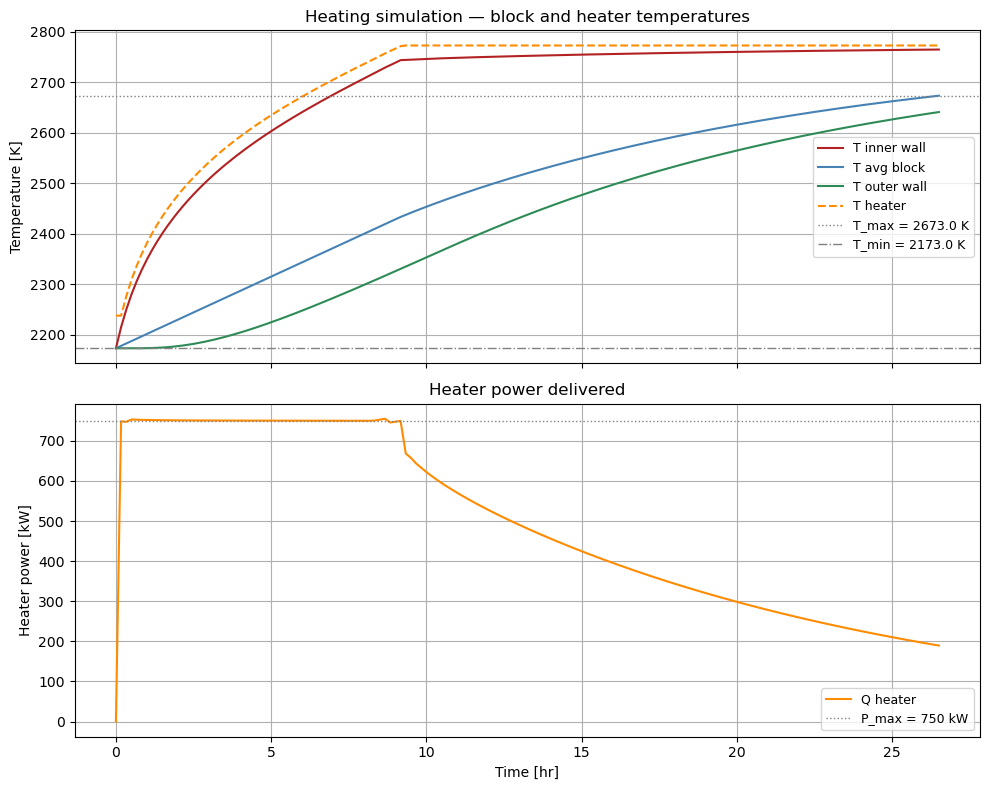

In [73]:
fig, (ax_T, ax_Q) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

_t_hr = _heat_res['time'] / 3600

# -- Temperature plot ---------------------------------------------------------
ax_T.plot(_t_hr, _heat_res['T_inner'], label='T inner wall', color='firebrick')
ax_T.plot(_t_hr, _heat_res['T_avg'],   label='T avg block',  color='steelblue')
ax_T.plot(_t_hr, _heat_res['T_outer'], label='T outer wall', color='seagreen')
if _heat_res['T_liner'].any():
    ax_T.plot(_t_hr, _heat_res['T_liner'], label='T liner', color='mediumpurple', linestyle='--')
ax_T.plot(_t_hr, _heat_res['T_heater'],label='T heater',     color='darkorange', linestyle='--')
ax_T.axhline(_T_block_max, color='grey', linestyle=':', linewidth=1, label=f'T_max = {_T_block_max} K')
ax_T.axhline(_T_min,       color='grey', linestyle='-.', linewidth=1, label=f'T_min = {_T_min} K')
ax_T.set_ylabel('Temperature [K]')
ax_T.set_title('Heating simulation — block and heater temperatures')
ax_T.legend(fontsize=9)
ax_T.grid(True)

# -- Power plot ---------------------------------------------------------------
ax_Q.plot(_t_hr, _heat_res['Q_heater'] / 1e3, color='darkorange', label='Q heater')
ax_Q.axhline(_he_P_max / 1e3, color='grey', linestyle=':', linewidth=1,
             label=f'P_max = {_he_P_max/1e3:.0f} kW')
ax_Q.set_xlabel('Time [hr]')
ax_Q.set_ylabel('Heater power [kW]')
ax_Q.set_title('Heater power delivered')
ax_Q.legend(fontsize=9)
ax_Q.grid(True)

fig.tight_layout()
plt.show()


Hot zone: 198 sticks + 198 heaters, D_hot 38.7 m x H 10.0 m, fill 0.55, graphite 9,363 t, stored 2.60 GWh_th
  energy: N x E_stick_e = 1.165 GWh_e vs required 1.250 GWh_e (-6.8%, not resized)
Tank: D 40.8 m x H 20.0 m (withdrawal 4.5 m), bearing 88 kPa, foundation 103 kPa (allowable 225)
Columns: 310 @ 1.95 m pitch (332 kN each), graphite width 513 -> 135 mm x 230 mm (1.70 m) + oxide 481 mm wide (0.30 m), graphite 71 t, f_3D 0.85
Losses [kW]       side   edges     top  bottom (col / Thermax)   total   %/day
  peak (T_max)      721      76     452     796 ( 463 /  333)     2046    1.89
  cycle average     532      56     305     693 ( 434 /  260)     1587    1.46
Temperatures (peak, design-day air): shell 51 C, deck 37 C, joint 1200 C, floor avg 64 / max 73 / column spot 152 C (Annex M limit 200 C)
Floor air: 43.2 m3/s, dT 17.1 K, h_eff 42.9 W/m2K, fan 11.8 kW; peak q_bot 670 W/m2, cycle 590 W/m2
Capex (containment + insulation + supports + foundation): $12.4 / 19.9 / 29.8 M  = $7.66/kW

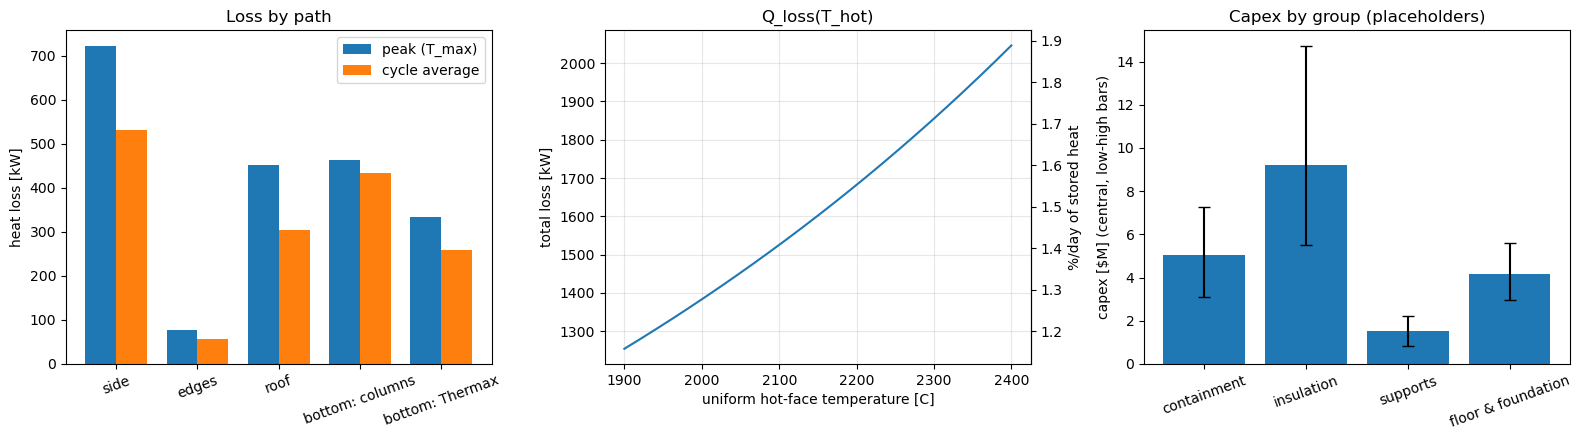

In [74]:
# ── System scale: steel tank, insulation, columns, floor cooling (thermal/tank.py) ──
# Uses the discharge above (`m`, `results`) and the YAML `tank:` block.
# P_stick = discharge-average power. Roof + floor losses were applied in the stick run
# (cell_sink, tank.block_axial_losses); side + edge losses are corrected post hoc (electricity
# lost ~ eta_block x heat lost).
from thermal.tank import stick_from_run, tank_system

tank_cfg = cfg.get('tank', {})
stick = stick_from_run(m, results)
tank = tank_system(stick, tank_cfg)
print(tank.summary())
if cell_sink is not None:     # provisional plant (used in the run) vs this plant
    _Tc = T_max - 273.15
    _q0, _q1 = sum(cell_sink.q(_Tc)) * cell_sink.f_open, sum(tank.cell_sink.q(_Tc)) * tank.cell_sink.f_open
    print(f"Cell-loss sink at T_max: provisional {_q0:.0f} vs final plant {_q1:.0f} W per m2 of graphite "
          f"({(_q0 / _q1 - 1) * 100:+.1f}%; rerun the discharge if this matters)")

# ── Plots: loss paths, loss vs hot-face temperature, capex by group ─────────────
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
paths = ['Q_side', 'Q_edge', 'Q_top', 'Q_bot_col', 'Q_bot_thx']
lbl = ['side', 'edges', 'roof', 'bottom: columns', 'bottom: Thermax']
x = np.arange(len(paths))
for k, (nm, d) in enumerate((('peak (T_max)', tank.loss_peak), ('cycle average', tank.loss_cycle))):
    ax[0].bar(x + (k - 0.5) * 0.38, [d[q] / 1e3 for q in paths], 0.38, label=nm)
ax[0].set_xticks(x); ax[0].set_xticklabels(lbl, rotation=20)
ax[0].set_ylabel('heat loss [kW]'); ax[0].set_title('Loss by path'); ax[0].legend()
Th = np.linspace(stick.T_min, stick.T_max, 25)
Ql = np.array([tank.loss_fn(t) for t in Th])
ax[1].plot(Th, Ql / 1e3)
_k = 1e3 * 86400 / tank.hz.E_th * 100          # kW -> %/day of stored heat
ax[1].secondary_yaxis('right', functions=(lambda q: q * _k, lambda y: y / _k)).set_ylabel('%/day of stored heat')
ax[1].set_xlabel('uniform hot-face temperature [C]'); ax[1].set_ylabel('total loss [kW]')
ax[1].set_title('Q_loss(T_hot)'); ax[1].grid(alpha=0.3)
g = tank.cost['groups']
names = list(g)
lo, mid, hi = (np.array([g[n][i] for n in names]) / 1e6 for i in range(3))
ax[2].bar(names, mid, yerr=[mid - lo, hi - mid], capsize=4)
ax[2].set_ylabel('capex [$M] (central, low-high bars)'); ax[2].set_title('Capex by group (placeholders)')
ax[2].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()


In [10]:
#gnerate a new vane heat fraction table and save it to a file

from thermal.correlations import run_vane_study, vane_heat_fraction, load_vane_table

rows, table, errs = run_vane_study(
    prm={'thicknesses': (0.005, 0.01, 0.02, 0.04, 0.05),   # vane thicknesses [m]
         'S': 1.3,                                   # cavity side [m]
         'gap': 0.003175,                               # closed corner gap [m]
         'T_bottom': 2100, 'T_top': 2000},           # wall temperature profile [K]
    out='my_vane_study.npz')

vane_heat_fraction(5, 2.0, t_vane=0.015, table=table)   # use the new fits right away
table = load_vane_table('my_vane_study.npz')             # or reload them later


H = 3.0 m (H/L = 1.00): no vanes Q_stick 215.2 kW, lower block 0.0 kW  [2 s]
H = 6.0 m (H/L = 2.00): no vanes Q_stick 199.8 kW, lower block 86.9 kW  [1 s]
H = 10.0 m (H/L = 3.33): no vanes Q_stick 192.9 kW, lower block 61.2 kW  [1 s]

=== vane t = 5.00 mm, R'' = 0.006186 m2K/W (k at 2050 K) | cavity side 1.3 m, vane l = 32.25 / 45.61 cm, liner side 31.54 cm, closed gap 3.17 mm, rays 32768
  H  3.0 theta   0.0: heat fraction 0.7045  cell 0.7017  lower-block share 0.000 (no vanes 0.000)  T_liner_in 1907 K  [7 s]
  H  3.0 theta   2.0: heat fraction 0.7395  cell 0.7370  lower-block share 0.000 (no vanes 0.000)  T_liner_in 1920 K  [6 s]
  H  3.0 theta   5.0: heat fraction 0.8019  cell 0.8000  lower-block share 0.000 (no vanes 0.000)  T_liner_in 1942 K  [5 s]
  H  3.0 theta  10.0: heat fraction 0.8583  cell 0.8569  lower-block share 0.000 (no vanes 0.000)  T_liner_in 1960 K  [5 s]
  H  3.0 theta  20.0: heat fraction 0.9107  cell 0.9098  lower-block share 0.000 (no vanes 0.000)  T_liner_in 19

KeyboardInterrupt: 

In [6]:
# -- Find area_ratio such that avg Q in pseudo-steady-state = avg_power ------
# Pseudo-steady-state (PSS) begins when T_inner - T_avg stops becoming more
# negative, i.e. at the minimum of delta = T_inner - T_avg (peak gradient).
# We average Q_cell from that point until SOC = 0, and bisect on area_ratio
# until that average equals the design value avg_power.

# ── Load all inputs from YAML (no reliance on other cells' kernel variables) ─
with open('tinless_model_input.yaml') as _f:
    _cfg = yaml.safe_load(_f)

_s = _cfg['storage']
_p = _cfg['powerstick']

_end_time    = _cfg['end_time']
_dt_short    = _cfg['dt_short']
_dt_medium   = _cfg['dt_medium']
_dt_long     = _cfg['dt_long']
_sub_steps   = _cfg['sub_steps']
_T_sur       = _cfg['T_sur']
_liner_bool  = _cfg['liner_bool']
_blk_loss    = _cfg['block_heat_loss_bool']

_raw_emis    = _cfg['emissivity_tables'][0]['value']
_emis_table  = [(tuple(row[0]), float(row[1]), float(row[2]), float(row[3]))
                for row in _raw_emis]

_avg_flux    = _s['avg_flux']
_duration_hr = _s['duration_hr']
_T_min       = _s['T_min']
_dT_range    = _s['block_temp_range']
_L           = _s['L']
_th_ins      = _s['th_ins']
_num_ax      = _s['num_ax_segments']
_num_rad     = _s['num_rad_segments']

_side_len    = _p['side_len']
_T_ps        = _p['cooling_temp']
#_panel_eff   = _p['panel_efficiency']
_f_bare      = _p['f_bare']
_f_active       = _p['f_active']
_liner_side_len    = _p['liner_side_len']

_sh                = _cfg.get('shade', {})
_shade_bool       = _sh.get('shade_bool', _cfg.get('shade_bool', False))
_liner_to_shade_ratio        = _sh.get('liner_to_shade_perimeter_ratio', None)
_shade_side_len              = _liner_to_shade_ratio * _liner_side_len if _liner_to_shade_ratio else None
_shade_thickness             = _sh.get('thickness', 0.05)
_shade_surface_emissivity = _sh.get('surface_emissivity', 0.8)
_shade_outer_foil         = _sh.get('outer_foil', False)
_shade_num_conduction_layers = _sh.get('num_conduction_layers', 5)
_corner_gap                   = _sh.get('corner_gap', 0.003175)
_shade_perimeter_c           = _liner_to_shade_ratio * 4 * _liner_side_len if _liner_to_shade_ratio else None
_f_shade_min                 = 8 * _shade_thickness / _shade_perimeter_c if _shade_perimeter_c else 0.03
_f_shade_max                 = 1 - 8 * _corner_gap / _shade_perimeter_c   if _shade_perimeter_c else 0.99

# ── Derived quantities ────────────────────────────────────────────────────────
_T_max      = _T_min + _dT_range
_r_ps_eff   = 2 * _side_len / np.pi
_A_ps       = 4 * _side_len * _L           # total powerstick surface area [m^2]
_f_cell     = (1.0 - _f_bare) * _f_active
_f_inact    = (1.0 - _f_bare) * (1.0 - _f_active)
_ps_tmp_    = PowerStick(axial_steps=1, width=_side_len, height=_L,
                        cooling_temp=_T_ps,
                        f_bare=_f_bare, f_active=_f_active,
                        liner_bool=_liner_bool, liner_width=_liner_side_len,
                        emissivity_table=_emis_table)
_inc_bins_, _, _ = _ps_tmp_.incident_energy(_T_min-100, 1 / area_ratio)
_inc_tot_   = sum(_inc_bins_.values())
_f_Q        = sum(
    _inc_bins_[row[0]] / _inc_tot_ * _f_cell * row[1]
    / (_f_bare * row[2] + _f_cell * row[1] + _f_inact * row[3])
    for row in _emis_table)
_e_dens     = storage_rho(_T_min + _dT_range / 2) * storage_cp(_T_min + _dT_range / 2) * _dT_range
_V_block    = _avg_flux * 1e4 * _A_ps * _f_cell / _f_Q * _duration_hr * 3600 / _e_dens
_avg_power  = _avg_flux * 1e4 * _A_ps * _f_cell  # cell-weighted target [W]

print(f"V_block = {_V_block:.3f} m^3  |  avg_power target = {_avg_power/1e3:.1f} kW")
print(f"T_min = {_T_min} K  T_max = {_T_max} K  duration = {_duration_hr} hr")

# ── Bisection objective ───────────────────────────────────────────────────────
def simulate_pss_avg_power(area_ratio):
    r_in_     = _r_ps_eff * area_ratio
    r_out_    = np.sqrt(_V_block / (np.pi * _L) + r_in_**2)
    init_dist = np.full((_num_ax, _num_rad), float(_T_max))
    block_    = GraphiteBlock(init_dist, inner_radius=r_in_, outer_radius=r_out_,
                              length=_L, th_ins=_th_ins)
    pipe_     = Pipe(OD=0.02, length=_L, wall_thickness=0.001, roughness=1e-5, th_ins=0.0)
    storage_  = StorageModule(N_pipes=1, Pipe=pipe_, Block=block_,
                              num_ax_segments=_num_ax, num_rad_segments=_num_rad,
                              bypass_range=[0, 1])
    ps_       = PowerStick(axial_steps=_num_ax, width=_side_len, height=_L,
                           cooling_temp=_T_ps,
                           f_bare=_f_bare, f_active=_f_active,
                           liner_bool=_liner_bool, liner_width=_liner_side_len,
                           emissivity_table=_emis_table)
    sim_      = TinlessSimulation(storage_, ps_, T_sur=_T_sur,
                                  block_heat_loss=_blk_loss,
                                  shade_bool=_shade_bool,
                                  shade_side_len=_shade_side_len,
                                  shade_thickness=_shade_thickness,
                                  shade_surface_emissivity=_shade_surface_emissivity,
                                  shade_outer_foil=_shade_outer_foil,
                                  shade_num_conduction_layers=_shade_num_conduction_layers,
                                  f_shade_min=_f_shade_min,
                                  f_shade_max=_f_shade_max,
                                  nominal_cell_flux=_avg_flux)
    res_      = sim_.run_simulation(end_time=_end_time,
                                dt_short=_dt_short, dt_medium=_dt_medium, dt_long=_dt_long,
                                sub_steps=_sub_steps, dt_short_duration=0)

    delta = res_['T_inner'] - res_['T_avg']
    soc   = (res_['T_avg'] - _T_min) / _dT_range

    #idx_pss  = int(np.argmin(delta))
    idx_pss = int(0)
    t_pss_hr = res_['time'][idx_pss] / 3600

    soc0_mask = np.where(soc <= 0)[0]
    if len(soc0_mask) > 0:
        idx_soc0  = int(soc0_mask[0])
        t_soc0_hr = res_['time'][idx_soc0] / 3600
        soc0_str  = f'SOC=0 @ {t_soc0_hr:.1f} hr'
    else:
        idx_soc0 = len(soc) - 1
        soc0_str = f'SOC={soc[-1]:.2f} at end (never reached 0)'

    if idx_pss >= idx_soc0:
        avg_Q = float(res_['Q_cell'][idx_pss])
    else:
        avg_Q = float(res_['Q_cell'][idx_pss:idx_soc0 + 1].mean())

    print(f'  area_ratio = {area_ratio:6.3f}  '
          f'PSS @ {t_pss_hr:.1f} hr  {soc0_str}  '
          f'avg_Q = {avg_Q/1e3:.2f} kW  (target {_avg_power/1e3:.2f} kW)')
    return avg_Q - _avg_power

# ── Bisection ─────────────────────────────────────────────────────────────────
_pwr_tol = 0.01
_ar_guess = 10.0

print('Searching for area_ratio where avg PSS Q_cell = avg_power...')
f0 = simulate_pss_avg_power(_ar_guess)

if abs(f0) / _avg_power <= _pwr_tol:
    ar_opt = _ar_guess
else:
    if f0 > 0:          # too much heat -> need smaller area_ratio
        ar_hi, f_hi = _ar_guess, f0
        ar_lo = _ar_guess
        while True:
            ar_lo /= 2
            f_lo = simulate_pss_avg_power(ar_lo)
            if f_lo <= 0:
                break
            ar_hi, f_hi = ar_lo, f_lo
    else:               # too little heat -> need larger area_ratio
        ar_lo, f_lo = _ar_guess, f0
        ar_hi = _ar_guess
        while True:
            ar_hi *= 2
            f_hi = simulate_pss_avg_power(ar_hi)
            if f_hi >= 0:
                break
            ar_lo, f_lo = ar_hi, f_hi

    print(f'Bracket: [{ar_lo:.3f}, {ar_hi:.3f}]')

    for _ in range(20):
        ar_mid = (ar_lo + ar_hi) / 2
        f_mid  = simulate_pss_avg_power(ar_mid)
        if abs(f_mid) / _avg_power <= _pwr_tol:
            break
        if f_mid > 0:
            ar_hi = ar_mid
        else:
            ar_lo = ar_mid

    ar_opt = (ar_lo + ar_hi) / 2

_r_in_opt  = _r_ps_eff * ar_opt
_r_out_opt = np.sqrt(_V_block / (np.pi * _L) + _r_in_opt**2)
print()
print(f'Optimal area_ratio = {ar_opt:.3f}')
print(f'  r_in  = {_r_in_opt:.4f} m   D_in  = {2*_r_in_opt:.4f} m')
print(f'  r_out = {_r_out_opt:.4f} m   D_out = {2*_r_out_opt:.4f} m')
print(f'  VF    = {1/ar_opt:.4f}')


V_block = 25.875 m^3  |  avg_power target = 203.3 kW
T_min = 2073 K  T_max = 2573 K  duration = 50 hr
Searching for area_ratio where avg PSS Q_cell = avg_power...


ValueError: shade geometry infeasible: r_shade=489.02 mm < minimum 489.05 mm (= (1+√2/2) × r_liner). Open shade panels would clip the liner corners. Set shade_side_len ≥ 768.20 mm.

In [68]:
# -- Smallest heater cavity that charges within heater.charge_hr ------------------
# Charge time falls as the cavity grows (more wall area -> lower heater temperature
# for the same power) and flattens at the power limit E_block / max power. Search for
# the smallest heater.area_ratio (= D_cavity / D_heater) with t_charge <= target. The
# graphite per cell is fixed (= stick cell), so a bigger cavity only adds open area.
import copy
from thermal.build import build_tinless as _bt, build_heater as _bh, load_config as _lc
from thermal.tank import cell_loss_sink as _cls

_cfg = _lc('tinless_model_input.yaml')
_m   = _bt(_cfg, geometry_only=True)
_target_hr = _cfg['heater'].get('charge_hr') or _cfg['end_time'] / 3600
_losses = bool(_cfg.get('tank')) and _cfg['tank'].get('block_axial_losses', True)


def charge_time_hr(area_ratio):
    """Charge time [h] at this heater.area_ratio (inf if not charged in 3x target)."""
    hm = _bh(_m, area_ratio=area_ratio)
    sink = None
    if _losses:   # the heater cavity changes the open-area factor of the roof / floor loss
        cfg_ = copy.deepcopy(_cfg); cfg_['heater']['area_ratio'] = area_ratio
        sink = _cls(_bt(cfg_, geometry_only=True), cfg_['tank']).for_storage(hm.storage)
    r = hm.sim.run_heating_simulation(hm.heater, end_time=3 * _target_hr * 3600, Q_sink_fn=sink,
                                      **hm.run_kwargs)
    Ta, t = r['T_avg'], r['time'] / 3600
    t_c = float(np.interp(hm.T_max, Ta[-2:], t[-2:])) if Ta[-1] >= hm.T_max else np.inf
    print(f'  area_ratio {area_ratio:6.3f}: cavity D {2*hm.r_in:.3f} m -> charge {t_c:6.2f} h '
          f'(heater peak {r["T_heater"].max():.0f} K)')
    return t_c


_hm0 = _bh(_m)
_E_block = storage_rho(_hm0.T_max) * storage_cp(_hm0.T_max) * _hm0.V * (_hm0.T_max - _hm0.T_min)
_t_floor = _E_block / _hm0.heater.max_power / 3600
print(f'Target charge time {_target_hr:.1f} h; power-limited minimum {_t_floor:.1f} h '
      f'({_E_block/3.6e6:,.0f} kWh_th at {_hm0.heater.max_power/1e3:.0f} kW)')

ar_opt = None
if _t_floor > _target_hr:
    print('Infeasible: the target is below the power-limited minimum -> raise heater.max_power_per_m')
else:
    ar_hi = float(_cfg['heater']['area_ratio'])
    for _ in range(6):                        # grow until the target is met
        if charge_time_hr(ar_hi) <= _target_hr:
            break
        ar_hi *= 1.5
    else:
        ar_hi = None
        print('Not reached by 11x the YAML area_ratio: heater max_temperature too close to block T_max?')
    if ar_hi is not None:
        ar_lo = 1.05                          # heater just fits in the cavity
        if charge_time_hr(ar_lo) <= _target_hr:
            ar_opt = ar_lo
        else:
            while ar_hi / ar_lo > 1.01:       # 1% in area_ratio
                ar_mid = np.sqrt(ar_lo * ar_hi)
                if charge_time_hr(ar_mid) <= _target_hr:
                    ar_hi = ar_mid
                else:
                    ar_lo = ar_mid
            ar_opt = ar_hi

if ar_opt is not None:
    _hm_opt = _bh(_m, area_ratio=ar_opt)
    print(f'\nSmallest heater area_ratio = {ar_opt:.3f}: cavity D {2*_hm_opt.r_in:.3f} m '
          f'({np.pi*_hm_opt.r_in**2:.3f} m2), graphite r_out {_hm_opt.r_out:.3f} m')


Target charge time 30.0 h; power-limited minimum 17.5 h (13,135 kWh_th at 750 kW)
Block fully charged: T_avg=2673.0 K >= 2673.0 K at t=18.83 hr
  area_ratio  6.000: cavity D 1.146 m -> charge  18.83 h (heater peak 2773 K)
Block fully charged: T_avg=2673.5 K >= 2673.0 K at t=42.00 hr
  area_ratio  1.050: cavity D 0.201 m -> charge  41.87 h (heater peak 2773 K)
Block fully charged: T_avg=2673.9 K >= 2673.0 K at t=28.17 hr
  area_ratio  2.510: cavity D 0.479 m -> charge  28.03 h (heater peak 2773 K)
Block fully charged: T_avg=2673.2 K >= 2673.0 K at t=35.00 hr
  area_ratio  1.623: cavity D 0.310 m -> charge  34.96 h (heater peak 2773 K)
Block fully charged: T_avg=2673.4 K >= 2673.0 K at t=31.50 hr
  area_ratio  2.019: cavity D 0.386 m -> charge  31.43 h (heater peak 2773 K)
Block fully charged: T_avg=2673.8 K >= 2673.0 K at t=29.83 hr
  area_ratio  2.251: cavity D 0.430 m -> charge  29.70 h (heater peak 2773 K)
Block fully charged: T_avg=2673.6 K >= 2673.0 K at t=30.67 hr
  area_ratio  2.

In [ ]:
import thermal.components as _tc
from scipy.integrate import cumulative_trapezoid

# ── Fixed design parameters ──────────────────────────────────────────────
_avg_flux        = 10          # W/cm^2
_duration_hr     = 50          # hr  (fixed discharge duration)
_side_len        = 0.13        # m
_L               = 3.0         # m
_th_ins          = 0.0         # m
_num_ax          = 2
_num_rad         = 10
_T_ps            = 323         # K
_f_bare          = 0
_f_active        = 0.83
_T_sur            = 300         # K
_dt              = 1200        # s
_sub_steps       = 5
_pwr_tol         = 0.01        # bisection tolerance (fraction of avg_power)
_T_max           = 2173        # K  (block full/maximum temperature)
_liner_side_len  = 0.20        # m  (square side length of tungsten liner)

_r_ps_eff      = 2 * _side_len / np.pi
_avg_power = _avg_flux * 1e4 * 4 * _side_len * _L * (1.0 - _f_bare) * _f_active  # cell-weighted [W]

# ── Sweep parameters ─────────────────────────────────────────────────────
liner_bool_vals = [False, True]           # tungsten liner on/off
#liner_bool_vals = [True]           # tungsten liner on/off
temp_range_vals = [250, 375, 500]         # K  (block operating temperature swing)
#temp_range_vals = [300]         # K  (block operating temperature swing)
bandgap_vals    = [1.24, 1.38, 1.55]     # microns
#bandgap_vals    = [1.55]     # microns

# ── Helpers ───────────────────────────────────────────────────────────────
def _build_and_run(T_max, dT_range, area_ratio, emis_table, liner_bool_):
    """
    Size a graphite storage block and run a full transient discharge simulation.

    T_min = T_max - dT_range.
    Block volume is sized from the required energy; inner radius follows from
    area_ratio = r_in / r_ps_eff; outer radius derived from V_block and r_in.
    """
    T_min     = T_max - dT_range
    T_avg_mid = T_min + dT_range / 2
    e_dens_   = storage_rho(T_avg_mid) * storage_cp(T_avg_mid) * dT_range
    f_cell_      = (1.0 - _f_bare) * _f_active
    f_inact_     = (1.0 - _f_bare) * (1.0 - _f_active)
    ps_tmp_      = PowerStick(axial_steps=1, width=_side_len, height=_L,
                             cooling_temp=_T_ps,
                             f_bare=_f_bare, f_active=_f_active,
                             liner_bool=liner_bool_, liner_width=_liner_side_len,
                             emissivity_table=emis_table)
    inc_bins_, _, _ = ps_tmp_.incident_energy(T_min, 1.0)
    inc_tot_     = sum(inc_bins_.values())
    f_Q_         = sum(
        inc_bins_[row[0]] / inc_tot_ * f_cell_ * row[1]
        / (_f_bare * row[2] + f_cell_ * row[1] + f_inact_ * row[3])
        for row in emis_table)
    tot_power_   = _avg_flux * 1e4 * 4 * _side_len * _L * f_cell_ / f_Q_
    V_blk_    = tot_power_ * _duration_hr * 3600 / e_dens_
    r_in_     = _r_ps_eff * area_ratio
    r_out_    = np.sqrt(V_blk_ / (np.pi * _L) + r_in_**2)

    init_dist_ = np.full((_num_ax, _num_rad), float(T_max))
    block_  = GraphiteBlock(init_dist_, inner_radius=r_in_, outer_radius=r_out_,
                            length=_L, th_ins=_th_ins)
    pipe_   = Pipe(OD=0.02, length=_L, wall_thickness=0.001, roughness=1e-5, th_ins=0.0)
    stor_   = StorageModule(N_pipes=1, Pipe=pipe_, Block=block_,
                            num_ax_segments=_num_ax, num_rad_segments=_num_rad,
                            bypass_range=[0, 1])
    ps_     = PowerStick(axial_steps=_num_ax, width=_side_len, height=_L,
                         cooling_temp=_T_ps,
                         f_bare=_f_bare, f_active=_f_active,
                         liner_bool=liner_bool_, liner_width=_liner_side_len,
                         emissivity_table=emis_table)
    sim_    = TinlessSimulation(stor_, ps_, T_sur=_T_sur, block_heat_loss=False)
    res_    = sim_.run_simulation(end_time=_duration_hr * 3600, dt=_dt, sub_steps=_sub_steps)
    return res_, r_out_

def _pss_avg_q(res_, dT_range, T_max):
    """
    Compute average cell heat flux over the pseudo-steady-state window.
    PSS onset fixed at t=0; window ends when SOC drops to zero.
    """
    T_min    = T_max - dT_range
    soc      = (res_['T_avg'] - T_min) / dT_range
    idx_pss  = int(0)
    soc0     = np.where(soc <= 0)[0]
    idx_soc0 = int(soc0[0]) if len(soc0) else len(soc) - 1
    if idx_pss >= idx_soc0:
        return float(res_['Q_cell'][idx_pss])
    return float(res_['Q_cell'][idx_pss:idx_soc0 + 1].mean())

# ── Main sweep ───────────────────────────────────────────────────────────
sweep_results = {}
total = len(liner_bool_vals) * len(bandgap_vals) * len(temp_range_vals)
n = 0

for liner_bool_ in liner_bool_vals:
    for bg_val in bandgap_vals:
        emis_table_bg = [
            ((0.1,    bg_val), 0.9,  0.1, 0.1),
            ((bg_val, 20.0),   0.05, 0.1, 0.1),
        ]
        for dT_range in temp_range_vals:
            n += 1
            print(f'[{n}/{total}] liner={liner_bool_}  dT={dT_range}K  T_min={_T_max - dT_range}K  bg={bg_val}um  -- bisecting area_ratio')

            try:
                def _f(ar, _Tmax=_T_max, _dT=dT_range, _emis=emis_table_bg, _lb=liner_bool_):
                    res_, _ = _build_and_run(_Tmax, _dT, ar, _emis, _lb)
                    q = _pss_avg_q(res_, _dT, _Tmax)
                    print(f'    ar={ar:.3f}  avg_Q={q/1e3:.1f} kW  (target {_avg_power/1e3:.0f} kW)')
                    return q - _avg_power

                f0 = _f(10.0)
                if abs(f0) / _avg_power <= _pwr_tol:
                    ar_opt = 10.0
                else:
                    if f0 > 0:
                        ar_hi, f_hi = 10.0, f0
                        ar_lo = 10.0
                        while True:
                            ar_lo /= 2
                            f_lo = _f(ar_lo)
                            if f_lo <= 0:
                                break
                            ar_hi, f_hi = ar_lo, f_lo
                    else:
                        ar_lo, f_lo = 10.0, f0
                        ar_hi = 10.0
                        while True:
                            ar_hi *= 2
                            f_hi = _f(ar_hi)
                            if f_hi >= 0:
                                break
                            ar_lo, f_lo = ar_hi, f_hi

                    for _ in range(20):
                        ar_mid = (ar_lo + ar_hi) / 2
                        f_mid  = _f(ar_mid)
                        if abs(f_mid) / _avg_power <= _pwr_tol:
                            break
                        if f_mid > 0:
                            ar_hi = ar_mid
                        else:
                            ar_lo = ar_mid
                    ar_opt = (ar_lo + ar_hi) / 2

                res_opt, r_out_opt = _build_and_run(_T_max, dT_range, ar_opt, emis_table_bg, liner_bool_)
                Q  = res_opt['Q_rad']
                Q_cell = res_opt['Q_cell']
                Pe = res_opt['P_elec']
                Ti = res_opt['T_inner']
                Ta = res_opt['T_avg']
                t  = res_opt['time']
                cum_Q = cumulative_trapezoid(Q,  t, initial=0)
                cum_Q_cell = cumulative_trapezoid(Q_cell, t, initial=0)
                cum_P = cumulative_trapezoid(Pe, t, initial=0)
                eff   = cum_P[-1] / cum_Q[-1] * 100 if cum_Q[-1] > 0 else 0.0
                eff_cell = cum_P[-1] / cum_Q_cell[-1] * 100 if cum_Q_cell[-1] > 0 else 0.0

                sweep_results[(dT_range, bg_val, liner_bool_)] = dict(
                    area_ratio = ar_opt,
                    r_out      = r_out_opt,
                    peak_dT    = float(np.max(Ta - Ti)),
                    peak_power = float(np.max(Q)) / 1e3,
                    min_power  = float(np.min(Q)) / 1e3,
                    efficiency = eff,
                    efficiency_cell = eff_cell,
                    avg_cell_flux  = float(Q_cell.mean()) / (4 * _side_len * _L * (1.0 - _f_bare) * _f_active * 1e4),
                )
                print(f'    -> ar_opt={ar_opt:.3f}  r_out={r_out_opt:.3f}m  '
                      f'peak_Q={np.max(Q)/1e3:.0f}kW  eff={eff:.1f}%')
            except Exception as e:
                print(f'    ERROR ({type(e).__name__}): {e} — skipping')

print('Sweep complete.')


[1/18] liner=False  dT=250K  T_min=1923K  bg=1.24um  -- bisecting area_ratio
    ERROR (TypeError): TinlessSimulation.run_simulation() got an unexpected keyword argument 'dt' — skipping
[2/18] liner=False  dT=375K  T_min=1798K  bg=1.24um  -- bisecting area_ratio
    ERROR (TypeError): TinlessSimulation.run_simulation() got an unexpected keyword argument 'dt' — skipping
[3/18] liner=False  dT=500K  T_min=1673K  bg=1.24um  -- bisecting area_ratio
    ERROR (TypeError): TinlessSimulation.run_simulation() got an unexpected keyword argument 'dt' — skipping
[4/18] liner=False  dT=250K  T_min=1923K  bg=1.38um  -- bisecting area_ratio
    ERROR (TypeError): TinlessSimulation.run_simulation() got an unexpected keyword argument 'dt' — skipping
[5/18] liner=False  dT=375K  T_min=1798K  bg=1.38um  -- bisecting area_ratio
    ERROR (TypeError): TinlessSimulation.run_simulation() got an unexpected keyword argument 'dt' — skipping
[6/18] liner=False  dT=500K  T_min=1673K  bg=1.38um  -- bisecting area

In [ ]:
dT_colors    = plt.cm.plasma(np.linspace(0.15, 0.85, len(temp_range_vals)))
liner_styles = {False: '-', True: '--'}
liner_labels = {False: 'no liner', True: 'W liner'}

fig, axes = plt.subplots(4, 2, figsize=(12, 18))

ax_ar,  ax_rout    = axes[0]
ax_eff,  ax_pwr     = axes[1]
ax_eff_c, ax_min_pwr = axes[2]
ax_bl2, ax_bl3     = axes[3]

for ci, dT_range in enumerate(temp_range_vals):
    for liner_bool_ in liner_bool_vals:
        try:
            lbl    = f'ΔT={dT_range}K, {liner_labels[liner_bool_]}'
            kwargs = dict(color=dT_colors[ci], linestyle=liner_styles[liner_bool_],
                          marker='o', label=lbl)

            ax_ar.plot(      bandgap_vals, [sweep_results[(dT_range, bg, liner_bool_)]['area_ratio'] for bg in bandgap_vals], **kwargs)
            ax_rout.plot(    bandgap_vals, [sweep_results[(dT_range, bg, liner_bool_)]['r_out']      for bg in bandgap_vals], **kwargs)
            #ax_dT.plot(      bandgap_vals, [sweep_results[(dT_range, bg, liner_bool_)]['peak_dT']    for bg in bandgap_vals], **kwargs)
            ax_pwr.plot(     bandgap_vals, [sweep_results[(dT_range, bg, liner_bool_)]['peak_power'] / (4 * _side_len * _L * (1 - _f_bare) * _f_active * 10) for bg in bandgap_vals], **kwargs)
            ax_min_pwr.plot( bandgap_vals, [sweep_results[(dT_range, bg, liner_bool_)]['min_power']  / (4 * _side_len * _L * (1 - _f_bare) * _f_active * 10) for bg in bandgap_vals], **kwargs)
            ax_eff.plot(   bandgap_vals, [sweep_results[(dT_range, bg, liner_bool_)]['efficiency'] for bg in bandgap_vals], **kwargs)
            ax_eff_c.plot(   bandgap_vals, [sweep_results[(dT_range, bg, liner_bool_)]['efficiency_cell'] for bg in bandgap_vals], **kwargs)
            ax_bl2.plot(     bandgap_vals, [sweep_results[(dT_range, bg, liner_bool_)]['avg_cell_flux']    for bg in bandgap_vals], **kwargs)
        except KeyError:
            pass

ax_ar.set_ylabel('Optimal area ratio')
ax_ar.set_title('Optimal area ratio')
ax_rout.set_ylabel('Outer radius [m]')
ax_rout.set_title('Block outer radius')
#ax_dT.set_ylabel('Peak ΔT (inner − avg) [K]')
#ax_dT.set_title('Peak inner wall dT')
ax_pwr.set_ylabel('Peak power density [W/cm²]')
ax_pwr.set_title('Peak power (start of discharge)')
ax_min_pwr.set_ylabel('Min power density [W/cm²]')
ax_min_pwr.set_title('Min power (end of discharge)')
ax_eff.set_ylabel('Overall efficiency [%]')
ax_eff.set_title('Cumulative elec / thermal')
ax_eff_c.set_ylabel('Cell efficiency [%]')
ax_eff_c.set_title('Cumulative elec / cell thermal')
ax_bl2.set_ylabel('Avg cell flux [W/cm²]')
ax_bl2.set_title('Average cell power density')

for ax in [ax_ar, ax_rout, ax_pwr, ax_min_pwr, ax_eff, ax_eff_c, ax_bl2]:
    ax.set_xlabel('Bandgap [μm]')
    ax.grid(True)

for ax in [ax_bl3]:
    ax.set_visible(False)

ax_ar.legend(fontsize=9)
fig.suptitle(
    f'Parametric sweep  |  f_bare={_f_bare}  T_max={_T_max} K  dur={_duration_hr} hr  avg_flux={_avg_flux} W/cm²',
    fontsize=10,
)
fig.tight_layout()
plt.show()


r_ps_eff  = 8.28 cm
r_liner   = 19.10 cm
r_shield  = 20.37 cm
r_in      = 50.00 cm
A_cell    = 15600.0 cm²


c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:219: RuntimeWarning: divide by zero encountered in divide
  B_lin     = _B(T_liner)
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:227: RuntimeWarning: divide by zero encountered in divide
  n_ax       = self.storage.num_ax_segments


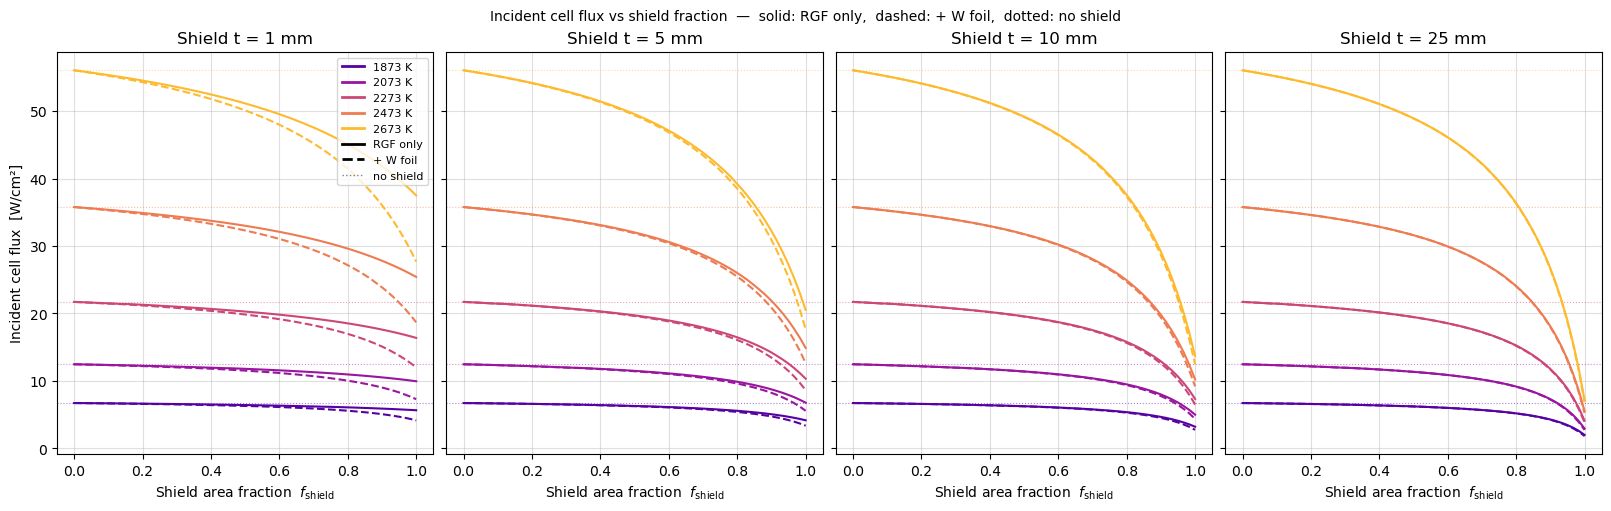


Cell flux [W/cm²] at f_shield = 0.5
     T_hot  no shield      t=1mm      t=5mm     t=10mm     t=25mm    t=1mm+W    t=5mm+W   t=10mm+W   t=25mm+W
      1873       6.73       6.44       6.30       6.26       6.24       6.30       6.27       6.26       6.24
      2073      12.47      11.81      11.52      11.44      11.38      11.56      11.47      11.42      11.38
      2273      21.72      20.32      19.78      19.63      19.53      19.90      19.69      19.61      19.53
      2473      35.78      33.07      32.11      31.88      31.72      32.39      32.00      31.84      31.71
      2673      56.05      51.26      49.72      49.37      49.13      50.26      49.57      49.32      49.12


In [ ]:
# -- Scratch: shade sensitivity -- incident cell flux vs f_shade -----------------
# Sweeps shade area fraction for different shade thicknesses.
# Compares RGF-only shade (solid) vs shade with W foil on outer face (dashed).
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# -- Inputs -------------------------------------------------------------------
side_len        = 0.13    # powerstick square side [m]
liner_side_len  = 0.30    # liner square side [m]
shade_side_len = 0.32    # shade square side [m]
r_in            = 0.50    # graphite inner-wall effective radius [m]
L               = 3.0     # axial length [m]
f_bare          = 0.0
f_active        = 1.0

band_gap = 1.24
emissivity_table = [
    ((0.1,      band_gap), 0.9,  0.10, 0.10),
    ((band_gap, 20.0    ), 0.05, 0.10, 0.10),
]

T_hot_vals     = [1873, 2073, 2273, 2473, 2673]  # graphite inner-wall temperatures [K]
thickness_vals = [0.001, 0.005, 0.010, 0.025]    # insulation thickness to sweep [m]
eps_sh         = 0.9
f_shade_arr   = np.linspace(0, 1, 60)

# -- Derived geometry ---------------------------------------------------------
r_ps_eff = 2 * side_len / np.pi
r_liner  = 2 * liner_side_len / np.pi
r_shade = 2 * shade_side_len / np.pi

VF_gr_liner   = r_liner  / r_in
VF_liner_ps   = r_ps_eff / r_liner
VF_gr_shade  = r_shade / r_in
VF_shade_lin = r_liner  / r_shade

height_step  = L
A_ps_seg     = 4 * side_len * L
A_liner_seg  = 2 * np.pi * r_liner  * height_step
A_shade_seg = 2 * np.pi * r_shade * height_step
A_gr_seg     = 2 * np.pi * r_in     * height_step
A_cell_cm2   = A_ps_seg * (1 - f_bare) * f_active * 1e4

print(f"r_ps_eff  = {r_ps_eff*100:.2f} cm")
print(f"r_liner   = {r_liner*100:.2f} cm")
print(f"r_shade  = {r_shade*100:.2f} cm")
print(f"r_in      = {r_in*100:.2f} cm")
print(f"A_cell    = {A_cell_cm2:.1f} cm\u00b2")

# -- Mock sim object ----------------------------------------------------------
class _M:
    pass

def _make_sim(thickness, foil=False):
    m = _M()
    m.powerstick                      = _M()
    m.powerstick.emissivity_table     = emissivity_table
    m.powerstick.liner_bool           = True
    m.powerstick.f_bare               = f_bare
    m.powerstick.f_active             = f_active
    m.VF                              = VF_gr_liner
    m.A_ps_seg                        = A_ps_seg
    m.shade_bool                     = True
    m.shade_thickness                = thickness
    m.shade_surface_emissivity = eps_sh
    m.shade_outer_foil         = foil
    m.liner_material            = 'tac'
    m.shade_num_conduction_layers    = 5
    m.VF_gr_liner                     = VF_gr_liner
    m.VF_liner_ps                     = VF_liner_ps
    m.A_liner_seg                     = A_liner_seg
    m.VF_gr_shade                    = VF_gr_shade
    m.VF_shade_lin                   = VF_shade_lin
    m.A_shade_seg                    = A_shade_seg
    m.A_gr_seg                        = A_gr_seg
    return m

# No-shade baseline (foil irrelevant)
sim_noshade = _make_sim(0.05)
sim_noshade.shade_bool = False

flux_noshade = {}
for T_hot in T_hot_vals:
    Q_ps, _, _ = TinlessSimulation.spectral_net_radiation(sim_noshade, T_hot, f_shade=0.0)
    flux_noshade[T_hot] = Q_ps / A_cell_cm2

# -- Sweep: (thickness, T_hot, foil) -> flux array over f_shade --------------
flux = {}
for thk in thickness_vals:
    for foil in [False, True]:
        sim = _make_sim(thk, foil=foil)
        for T_hot in T_hot_vals:
            vals = [
                TinlessSimulation.spectral_net_radiation(sim, T_hot, f_shade=fs)[0] / A_cell_cm2
                for fs in f_shade_arr
            ]
            flux[(thk, T_hot, foil)] = np.array(vals)

# -- Plot: one subplot per thickness ------------------------------------------
colors      = plt.cm.plasma(np.linspace(0.15, 0.85, len(T_hot_vals)))
foil_styles = {False: '-', True: '--'}

fig, axes = plt.subplots(1, len(thickness_vals), figsize=(16, 5), sharey=True,
                         constrained_layout=True)

for ax, thk in zip(axes, thickness_vals):
    for color, T_hot in zip(colors, T_hot_vals):
        for foil in [False, True]:
            ax.plot(f_shade_arr, flux[(thk, T_hot, foil)],
                    color=color, ls=foil_styles[foil], lw=1.5)
        ax.axhline(flux_noshade[T_hot], color=color, ls=':', lw=0.8, alpha=0.5)
    ax.set_title(f'Shade t = {thk*1000:.0f} mm')
    ax.set_xlabel('Shade area fraction  $f_{{\\mathrm{{shade}}}}$')
    ax.grid(True, alpha=0.4)

axes[0].set_ylabel('Incident cell flux  [W/cm\u00b2]')

# Legend: colors = T_hot, linestyle = foil variant
lh, ll = [], []
for color, T_hot in zip(colors, T_hot_vals):
    lh.append(Line2D([0],[0], color=color, lw=2))
    ll.append(f'{T_hot} K')
lh.append(Line2D([0],[0], color='k', ls='-',  lw=2));          ll.append('RGF only')
lh.append(Line2D([0],[0], color='k', ls='--', lw=2));          ll.append('+ W foil')
lh.append(Line2D([0],[0], color='k', ls=':',  lw=1, alpha=0.5)); ll.append('no shade')
axes[0].legend(lh, ll, fontsize=8, loc='upper right')

fig.suptitle(
    'Incident cell flux vs shade fraction  \u2014  solid: RGF only,  dashed: + W foil,  dotted: no shade',
    fontsize=10,
)
plt.show()

# -- Summary table at f_shade = 0.5 ------------------------------------------
fs_ref = 0.5
i_ref  = np.argmin(np.abs(f_shade_arr - fs_ref))
print(f"\nCell flux [W/cm\u00b2] at f_shade = {fs_ref}")
col_rgf = [f"t={thk*1000:.0f}mm" for thk in thickness_vals]
col_w   = [f"t={thk*1000:.0f}mm+W" for thk in thickness_vals]
header  = "  ".join(f"{h:>9}" for h in col_rgf + col_w)
print(f"{'T_hot':>10}  {'no shade':>9}  {header}")
for T_hot in T_hot_vals:
    rgf = "  ".join(f'{flux[(thk, T_hot, False)][i_ref]:>9.2f}' for thk in thickness_vals)
    wf  = "  ".join(f'{flux[(thk, T_hot, True )][i_ref]:>9.2f}' for thk in thickness_vals)
    print(f"{T_hot:>10}  {flux_noshade[T_hot]:>9.2f}  {rgf}  {wf}")


Saved efficiency_vs_temperature.csv


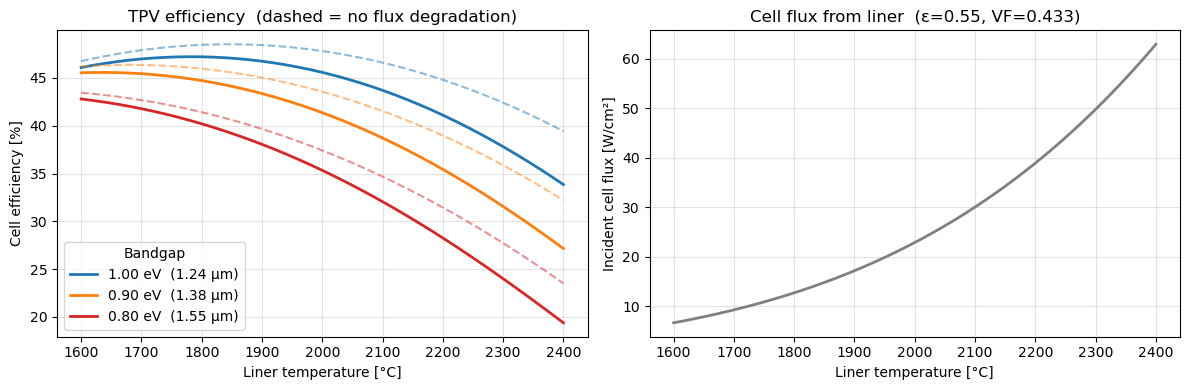

In [ ]:
# -- Cell efficiency vs emitter temperature — with flux degradation -----------
# Flux calculated via PowerStick.incident_energy() so powerstick emissivity
# table and view factor are applied correctly (not a blackbody assumption).
import csv, yaml, numpy as np, matplotlib.pyplot as plt
from thermal.properties import panel_efficiency

with open('tinless_model_input.yaml') as _f:
    _cfg = yaml.safe_load(_f)

_p              = _cfg['powerstick']
_s              = _cfg['storage']
_side_len       = _p['side_len']
_area_ratio     = _p['area_ratio']
_f_bare         = _p['f_bare']
_f_active       = _p['f_active']
_liner_side_len = _p['liner_side_len']
_L              = _s['L']
_num_ax         = _s['num_ax_segments']

_raw_emis   = _cfg['emissivity_tables'][0]['value']
_emis_table = [(tuple(r[0]), float(r[1]), float(r[2]), float(r[3])) for r in _raw_emis]

_r_ps_eff    = 2 * _side_len / np.pi
_r_in        = _r_ps_eff * _area_ratio
_r_liner     = 2 * _liner_side_len / np.pi
_VF_liner_ps = _r_ps_eff / _r_liner

# Build a single-step PowerStick (1 axial segment = full length)
_ps = PowerStick(axial_steps=1, width=_side_len, height=_L,
                 cooling_temp=300, f_bare=_f_bare, f_active=_f_active,
                 liner_bool=True, liner_width=_liner_side_len,
                 emissivity_table=_emis_table)

bandgaps = [1.24, 1.38, 1.55]
bg_eV    = [1.2398 / bg for bg in bandgaps]
T_C      = np.linspace(1600, 2400, 200)
T_K      = T_C + 273.15

# Compute flux_wcm2 at each temperature using incident_energy — same formula
# as generate_electricity_step so powerstick emissivity is properly applied.
def _flux_wcm2(T):
    inc_bins, _, _ = _ps.incident_energy(T, _VF_liner_ps)
    absorbed_cell = 0.0
    for i, (wr, ea, eb, ei) in enumerate(_emis_table):
        avg = _f_bare*eb + (1-_f_bare)*_f_active*ea + (1-_f_bare)*(1-_f_active)*ei
        if avg > 0:
            absorbed_cell += inc_bins[wr] * (1-_f_bare) * _f_active * ea / avg
    cell_flux_W = absorbed_cell * _ps.A_step
    return cell_flux_W / (_ps.A_step * (1-_f_bare) * _f_active * 1e4)

flux_wcm2 = np.array([_flux_wcm2(T) for T in T_K])

# Pre-compute efficiency arrays — reused for CSV and plot
eff_base_all = {bg: np.array([panel_efficiency(bg, T) * 100 for T in T_K])
                for bg in bandgaps}
eff_flux_all = {bg: np.array([panel_efficiency(bg, T, flux=f) * 100
                               for T, f in zip(T_K, flux_wcm2)])
                for bg in bandgaps}

# -- Export to CSV -----------------------------------------------------------
_csv_path = 'efficiency_vs_temperature.csv'
_headers  = (['T_C', 'flux_wcm2']
             + [f'eff_no_flux_{bg}um_pct'   for bg in bandgaps]
             + [f'eff_with_flux_{bg}um_pct' for bg in bandgaps])
with open(_csv_path, 'w', newline='') as _cf:
    _w = csv.writer(_cf)
    _w.writerow(_headers)
    for j in range(len(T_C)):
        _w.writerow(
            [round(T_C[j], 4), round(flux_wcm2[j], 6)]
            + [round(eff_base_all[bg][j], 6) for bg in bandgaps]
            + [round(eff_flux_all[bg][j], 6) for bg in bandgaps]
        )
print(f'Saved {_csv_path}')

# -- Plot --------------------------------------------------------------------
colors = ['C0', 'C1', 'C3']
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
for bg, eV, col in zip(bandgaps, bg_eV, colors):
    ax.plot(T_C, eff_base_all[bg], color=col, lw=1.5, ls='--', alpha=0.5)
    ax.plot(T_C, eff_flux_all[bg], color=col, lw=2, label=f'{eV:.2f} eV  ({bg} μm)')

ax.set_xlabel('Liner temperature [°C]')
ax.set_ylabel('Cell efficiency [%]')
ax.set_title('TPV efficiency  (dashed = no flux degradation)')
ax.legend(title='Bandgap')
ax.grid(True, alpha=0.35)

ax2 = axes[1]
ax2.plot(T_C, flux_wcm2, color='gray', lw=2)
ax2.set_xlabel('Liner temperature [°C]')
ax2.set_ylabel('Incident cell flux [W/cm²]')
ax2.set_title(f'Cell flux from liner  (ε=0.55, VF={_VF_liner_ps:.3f})')
ax2.grid(True, alpha=0.35)

fig.tight_layout()
plt.show()


Shield perimeter : 2.8970 m
f_shield_max     : 0.9912  (fully closed, 3.17 mm corner gaps)
f_shield_min     : 0.0276  (fully open,   10.0 mm panel thickness)


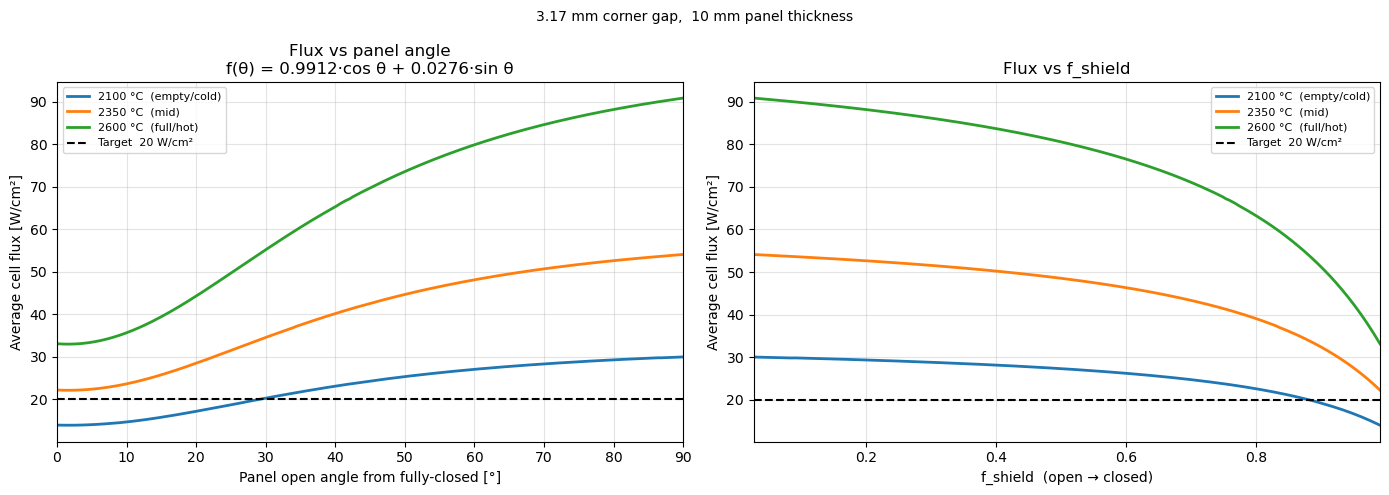

In [ ]:
# -- Shade panel open angle vs average cell flux ------------------------------
# The octagonal shade has 8 flat panels that pivot on their centre (axial)
# axis.  At angle θ from the fully-closed position each panel projects:
#
#   width_projected = W_panel * cos(θ) + thickness * sin(θ)
#
# Summing over all 8 panels and dividing by shade perimeter P:
#
#   f_shade(θ) = f_shade_max * cos(θ) + f_shade_min * sin(θ)
#
# Physical boundary conditions (not bisection bounds):
#   f_shade_max = (P - 8*g) / P   θ = 0°  (fully closed, corner gaps pass light)
#   f_shade_min =   8*t    / P    θ = 90° (fully open, only panel edge visible)
#
# g = corner_gap, t = shade thickness, P = shade perimeter = ratio * 4 * liner_side_len

import types, yaml, numpy as np, matplotlib.pyplot as plt
from thermal import PowerStick, TinlessSimulation

with open('tinless_model_input.yaml') as _f:
    _cfg = yaml.safe_load(_f)

_p  = _cfg['powerstick']
_s  = _cfg['storage']
_sh = _cfg.get('shade', {})

side_len       = _p['side_len']
area_ratio     = _p['area_ratio']
f_bare         = _p['f_bare']
f_active       = _p['f_active']
cooling_temp   = _p['cooling_temp']
liner_side_len = _p['liner_side_len']
L              = _s['L']
num_ax         = _s['num_ax_segments']
num_rad        = _s['num_rad_segments']
T_min          = _s['T_min']
T_swing        = _s['block_temp_range']
avg_flux       = _s['avg_flux']

liner_bool     = _cfg.get('liner_bool', True)
liner_material = _cfg.get('liner_material', 'tac')
shade_bool    = _sh.get('shade_bool', _cfg.get('shade_bool', False))
ratio          = _sh.get('liner_to_shade_perimeter_ratio', None)
shade_side_len = ratio * liner_side_len if ratio else None
shade_thick   = _sh.get('thickness', 0.01)
shade_emis       = _sh.get('surface_emissivity', 0.9)
shade_outer_foil = _sh.get('outer_foil', False)
shade_layers  = _sh.get('num_conduction_layers', 5)
corner_gap     = _sh.get('corner_gap', 0.003175)

shade_perimeter = ratio * 4 * liner_side_len if ratio else None
f_shade_max = 1 - 8 * corner_gap  / shade_perimeter  if shade_perimeter else 0.99
f_shade_min = 8 * shade_thick    / shade_perimeter   if shade_perimeter else 0.03

print(f'Shade perimeter : {shade_perimeter:.4f} m')
print(f'f_shade_max     : {f_shade_max:.4f}  (fully closed, {corner_gap*1e3:.2f} mm corner gaps)')
print(f'f_shade_min     : {f_shade_min:.4f}  (fully open,   {shade_thick*1e3:.1f} mm panel thickness)')

raw_emis   = _cfg['emissivity_tables'][0]['value']
emis_table = [(tuple(r[0]), float(r[1]), float(r[2]), float(r[3])) for r in raw_emis]

r_ps_eff = 2 * side_len / np.pi
r_in     = r_ps_eff * area_ratio

_storage = types.SimpleNamespace(
    block=types.SimpleNamespace(rad_in=r_in),
    num_ax_segments=num_ax,
)

ps = PowerStick(axial_steps=num_ax, width=side_len, height=L,
                cooling_temp=cooling_temp, f_bare=f_bare, f_active=f_active,
                liner_bool=liner_bool, liner_width=liner_side_len,
                emissivity_table=emis_table)

sim = TinlessSimulation(
    _storage, ps,
    T_sur=_cfg.get('T_sur', 300),
    block_heat_loss=_cfg.get('block_heat_loss_bool', False),
    shade_bool=shade_bool, shade_side_len=shade_side_len,
    shade_thickness=shade_thick,
    shade_surface_emissivity=shade_emis,
    shade_outer_foil=shade_outer_foil,
    shade_num_conduction_layers=shade_layers,
    f_shade_min=f_shade_min, f_shade_max=f_shade_max,
    nominal_cell_flux=avg_flux,
    liner_material=liner_material,
)

N         = 200

# Angle sweep: θ = 0° (fully closed) → 90° (fully open)
theta_deg    = np.linspace(0, 90, N)
theta_rad    = np.radians(theta_deg)
f_from_angle = f_shade_max * np.cos(theta_rad) + f_shade_min * np.sin(theta_rad)

# Direct f_shade sweep: linear from fully-open to fully-closed
f_direct = np.linspace(f_shade_min, f_shade_max, N)

A_cell_cm2 = ps.A_step * (1 - f_bare) * f_active * 1e4

T_walls   = [T_min, T_min + T_swing / 2, T_min + T_swing]
_suffixes = ['(empty/cold)', '(mid)', '(full/hot)']
T_labels  = [f'{_T - 273.15:.0f} \u00b0C  {_sfx}' for _T, _sfx in zip(T_walls, _suffixes)]

import warnings
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    for T_wall, label in zip(T_walls, T_labels):
        flux_angle = np.array([
            sim.spectral_net_radiation(T_wall, f_shade=f)[2] / A_cell_cm2
            for f in f_from_angle
        ])
        flux_fshade = np.array([
            sim.spectral_net_radiation(T_wall, f_shade=f)[2] / A_cell_cm2
            for f in f_direct
        ])
        ax1.plot(theta_deg, flux_angle,   lw=2, label=label)
        ax2.plot(f_direct,  flux_fshade, lw=2, label=label)

# Left: angle
ax1.axhline(avg_flux, ls='--', color='k', lw=1.5, label=f'Target  {avg_flux} W/cm\u00b2')
ax1.set_xlabel('Panel open angle from fully-closed [\u00b0]')
ax1.set_ylabel('Average cell flux [W/cm\u00b2]')
ax1.set_title(
    'Flux vs panel angle\n'
    f'f(\u03b8) = {f_shade_max:.4f}\u00b7cos \u03b8 + {f_shade_min:.4f}\u00b7sin \u03b8'
)
ax1.legend(fontsize=8)
ax1.set_xlim(0, 90)
ax1.grid(True, alpha=0.35)

# Right: f_shade
ax2.axhline(avg_flux, ls='--', color='k', lw=1.5, label=f'Target  {avg_flux} W/cm\u00b2')
ax2.set_xlabel('f_shade  (open \u2192 closed)')
ax2.set_ylabel('Average cell flux [W/cm\u00b2]')
ax2.set_title('Flux vs f_shade')
ax2.legend(fontsize=8)
ax2.set_xlim(f_shade_min, f_shade_max)
ax2.grid(True, alpha=0.35)

fig.suptitle(
    f'{corner_gap*1e3:.2f} mm corner gap,  {shade_thick*1e3:.0f} mm panel thickness',
    fontsize=10,
)
plt.tight_layout()
plt.show()


In [ ]:
# -- Scratch: parametric sweep  thickness x T_max x T_range x W-foil ---------
# Self-contained: reads config from YAML, rebuilds geometry for each case.
# thickness=0 -> shade_bool=False (no shade baseline); >0 -> insulating shade
# W foil (outer_foil) only applied when thickness > 0.
import yaml, numpy as np, matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from itertools import product

# -- Load YAML ----------------------------------------------------------------
with open('tinless_model_input.yaml') as _f:
    _cfg = yaml.safe_load(_f)

_end_time          = _cfg['end_time']
_dt_short          = _cfg['dt_short']
_dt_medium         = _cfg['dt_medium']
_dt_long           = _cfg['dt_long']
_dt_short_duration = _cfg.get('dt_short_duration', 3600)
_sub_steps         = _cfg['sub_steps']
_T_sur             = _cfg['T_sur']
_liner_bool        = _cfg['liner_bool']
_block_heat_loss   = _cfg['block_heat_loss_bool']

_raw_emis   = _cfg['emissivity_tables'][0]['value']
_emis_table = [(tuple(r[0]), float(r[1]), float(r[2]), float(r[3])) for r in _raw_emis]

_s            = _cfg['storage']
_avg_flux     = _s['avg_flux']
_duration_hr  = _s['duration_hr']
_L            = _s['L']
_th_ins       = _s['th_ins']
_num_ax       = _s['num_ax_segments']
_num_rad      = _s['num_rad_segments']

_p              = _cfg['powerstick']
_side_len       = _p['side_len']
_area_ratio     = _p['area_ratio']
_f_bare         = _p['f_bare']
_f_active       = _p['f_active']
_T_ps           = _p['cooling_temp']
_liner_side_len = _p['liner_side_len']

_sh                              = _cfg.get('shade', {})
_liner_to_shade_ratio           = _sh.get('liner_to_shade_perimeter_ratio', None)
_shade_side_len                 = _liner_to_shade_ratio * _liner_side_len if _liner_to_shade_ratio else None
_corner_gap                      = _sh.get('corner_gap', 0.003175)
_shade_perimeter_s              = _liner_to_shade_ratio * 4 * _liner_side_len if _liner_to_shade_ratio else None
_f_shade_max                    = 1 - 8 * _corner_gap / _shade_perimeter_s if _shade_perimeter_s else 0.99
_shade_surface_emissivity = _sh.get('surface_emissivity', 0.8)
_shade_num_conduction_layers    = _sh.get('num_conduction_layers', 5)

# -- Sweep parameters ---------------------------------------------------------
_thickness_sweep_mm = [0, 3, 5, 10]   # 0 = no shade
_T_max_sweep        = [2473, 2673, 2773]
_T_range_sweep      = [250, 500]
_foil_sweep         = [False, True]    # False = RGF only, True = W foil on outer face

# -- Fixed geometry -----------------------------------------------------------
_r_ps_eff   = 2 * _side_len / np.pi
_r_in       = _r_ps_eff * _area_ratio
_A_ps       = 4 * _side_len * _L
_f_cell_    = (1.0 - _f_bare) * _f_active
_f_inact_   = (1.0 - _f_bare) * (1.0 - _f_active)
_cell_area_cm2 = _A_ps * _f_cell_ * 1e4

_ps_tmp_ = PowerStick(axial_steps=1, width=_side_len, height=_L,
                      cooling_temp=_T_ps, f_bare=_f_bare, f_active=_f_active,
                      liner_bool=_liner_bool, liner_width=_liner_side_len,
                      emissivity_table=_emis_table)
_inc_bins_, _, _ = _ps_tmp_.incident_energy(min(_T_max_sweep) - max(_T_range_sweep) - 100, 1 / _area_ratio)
_inc_tot_ = sum(_inc_bins_.values())
_f_Q_ = sum(
    _inc_bins_[r[0]] / _inc_tot_ * _f_cell_ * r[1]
    / (_f_bare * r[2] + _f_cell_ * r[1] + _f_inact_ * r[3])
    for r in _emis_table)

_powerstick = PowerStick(
    axial_steps=_num_ax, width=_side_len, height=_L,
    cooling_temp=_T_ps, f_bare=_f_bare, f_active=_f_active,
    liner_bool=_liner_bool, liner_width=_liner_side_len,
    emissivity_table=_emis_table,
)

def _r_out(T_min, T_range):
    T_avg_ = T_min + T_range / 2
    E_req  = _avg_flux * 1e4 * _A_ps * _f_cell_ / _f_Q_ * _duration_hr * 3600
    e_dens = storage_rho(T_avg_) * storage_cp(T_avg_) * T_range
    V      = E_req / e_dens
    return np.sqrt(V / (np.pi * _L) + _r_in**2)

# -- Run all combinations -----------------------------------------------------
# key: (thk_mm, T_max, T_range, foil_bool)
# W foil only applies when shade is active (thk > 0)
_results = {}
_n_total  = (sum(len(_foil_sweep) if t > 0 else 1 for t in _thickness_sweep_mm)
             * len(_T_max_sweep) * len(_T_range_sweep))
_n_done   = 0
for _T_max, _T_range in product(_T_max_sweep, _T_range_sweep):
    _T_min  = _T_max - _T_range
    _ro     = _r_out(_T_min, _T_range)
    _T_init = _T_max
    for _thk_mm in _thickness_sweep_mm:
        _thk_m = _thk_mm / 1000.0
        _sb    = (_thk_mm > 0)
        _foils = _foil_sweep if _sb else [False]
        for _foil in _foils:
            _n_done += 1
            print(f'[{_n_done}/{_n_total}] t={_thk_mm} mm  T_max={_T_max}  '
                  f'\u0394T={_T_range}  foil={_foil}  r_out={_ro:.3f} m', flush=True)
            _block = GraphiteBlock(
                initial_temp_distribution=np.full((_num_ax, _num_rad), float(_T_init)),
                inner_radius=_r_in, outer_radius=_ro, length=_L, th_ins=_th_ins,
            )
            _pipe    = Pipe(OD=0.02, length=_L, wall_thickness=0.001, roughness=1e-5, th_ins=0.0)
            _storage = StorageModule(
                N_pipes=1, Pipe=_pipe, Block=_block,
                num_ax_segments=_num_ax, num_rad_segments=_num_rad, bypass_range=[0, 1],
            )
            _sim = TinlessSimulation(
                _storage, _powerstick, T_sur=_T_sur, block_heat_loss=_block_heat_loss,
                shade_bool=_sb, shade_side_len=_shade_side_len,
                shade_thickness=_thk_m,
                shade_surface_emissivity_inner=_shade_surface_emissivity_inner,
                shade_surface_emissivity_outer=_shade_surface_emissivity_outer,
                shade_outer_foil=_foil,
                shade_num_conduction_layers=_shade_num_conduction_layers,
                f_shade_min=(8 * _thk_m / _shade_perimeter_s) if (_shade_perimeter_s and _thk_m > 0) else 0.0,
                f_shade_max=_f_shade_max,
                nominal_cell_flux=_avg_flux,
            )
            _res = _sim.run_simulation(
                end_time=_end_time, dt_short=_dt_short, dt_medium=_dt_medium, dt_long=_dt_long,
                sub_steps=_sub_steps, dt_short_duration=_dt_short_duration,
            )
            _results[(_thk_mm, _T_max, _T_range, _foil)] = _res

print('All runs complete.')

# -- Metrics ------------------------------------------------------------------
from scipy.integrate import cumulative_trapezoid

def _metrics(res):
    flux  = res['Q_cell'] / _cell_area_cm2
    cum_Q = cumulative_trapezoid(res['Q_rad'],  res['time'], initial=0)
    cum_P = cumulative_trapezoid(res['P_elec'], res['time'], initial=0)
    eff   = cum_P[-1] / cum_Q[-1] * 100 if cum_Q[-1] > 0 else 0.0
    return eff, flux.max(), flux.min()

# -- Plot ---------------------------------------------------------------------
_cmap             = plt.cm.plasma
_T_max_colors     = {T: _cmap(i / max(len(_T_max_sweep) - 1, 1)) for i, T in enumerate(_T_max_sweep)}
_foil_styles      = {False: '-',  True: '--'}
_T_range_markers  = {T: m for T, m in zip(_T_range_sweep, ['o', '^'])}
_x_labels         = ['0\n(no shade)' if t == 0 else str(t) for t in _thickness_sweep_mm]
_metric_labels    = ['Overall cycle efficiency [%]', 'Max cell flux [W/cm$^2$]', 'Min cell flux [W/cm$^2$]']

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)

for (mi, mlbl), ax in zip(enumerate(_metric_labels), axes):
    for _T_max in _T_max_sweep:
        for _T_range in _T_range_sweep:
            for _foil in _foil_sweep:
                # thk=0 has no shade so foil is irrelevant; both curves share that baseline point
                y = [_metrics(_results[(_thk, _T_max, _T_range, _foil if _thk > 0 else False)])[mi]
                     for _thk in _thickness_sweep_mm]
                ax.plot(_thickness_sweep_mm, y,
                        color=_T_max_colors[_T_max],
                        ls=_foil_styles[_foil],
                        marker=_T_range_markers[_T_range],
                        lw=1.8, ms=5)
    ax.set_xlabel('Shade thickness [mm]')
    ax.set_ylabel(mlbl)
    ax.set_xticks(_thickness_sweep_mm)
    ax.set_xticklabels(_x_labels)
    ax.grid(True, alpha=0.35)

axes[0].set_title('Cycle efficiency')
axes[1].set_title('Max cell flux')
axes[2].set_title('Min cell flux')

# Split legend: colors = T_max, linestyle = foil, marker = T_range
_lh, _ll = [], []
for _T_max in _T_max_sweep:
    _lh.append(Line2D([0],[0], color=_T_max_colors[_T_max], lw=2))
    _ll.append(f'T_max={_T_max} K')
_lh.append(Line2D([0],[0], color='k', ls='-',  lw=2)); _ll.append('no W foil')
_lh.append(Line2D([0],[0], color='k', ls='--', lw=2)); _ll.append('W foil')
for _T_range in _T_range_sweep:
    _lh.append(Line2D([0],[0], color='k', marker=_T_range_markers[_T_range], ls='', ms=6))
    _ll.append(f'\u0394T={_T_range} K')
fig.legend(_lh, _ll, loc='lower center', ncol=len(_lh), fontsize=8, bbox_to_anchor=(0.5, -0.12))

fig.suptitle(
    'Parametric sweep: shade thickness \u00d7 T_max \u00d7 \u0394T_block  '
    '(\u2014 no W foil,  \u2013\u2013 W foil)',
    fontsize=11,
)
fig.tight_layout()
plt.show()


[1/42] t=0 mm  T_max=2473  ΔT=250  foil=False  r_out=2.895 m


c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:212: RuntimeWarning: divide by zero encountered in divide
  denom_out = VF_liner_ps * (1 - eps_L_in) / eps_L_in + 1 + (1 - avg_ps_emis) / avg_ps_emis
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:220: RuntimeWarning: divide by zero encountered in divide
  denom_out = VF_liner_ps * (1 - eps_L_in) / eps_L_in + 1 + (1 - avg_ps_emis) / avg_ps_emis


[2/42] t=3 mm  T_max=2473  ΔT=250  foil=False  r_out=2.895 m
[3/42] t=3 mm  T_max=2473  ΔT=250  foil=True  r_out=2.895 m
[4/42] t=5 mm  T_max=2473  ΔT=250  foil=False  r_out=2.895 m
[5/42] t=5 mm  T_max=2473  ΔT=250  foil=True  r_out=2.895 m
[6/42] t=10 mm  T_max=2473  ΔT=250  foil=False  r_out=2.895 m
[7/42] t=10 mm  T_max=2473  ΔT=250  foil=True  r_out=2.895 m
[8/42] t=0 mm  T_max=2473  ΔT=500  foil=False  r_out=2.129 m
[9/42] t=3 mm  T_max=2473  ΔT=500  foil=False  r_out=2.129 m
[10/42] t=3 mm  T_max=2473  ΔT=500  foil=True  r_out=2.129 m
[11/42] t=5 mm  T_max=2473  ΔT=500  foil=False  r_out=2.129 m
[12/42] t=5 mm  T_max=2473  ΔT=500  foil=True  r_out=2.129 m
[13/42] t=10 mm  T_max=2473  ΔT=500  foil=False  r_out=2.129 m
[14/42] t=10 mm  T_max=2473  ΔT=500  foil=True  r_out=2.129 m


KeyboardInterrupt: 

In [ ]:
# -- Scratch: w_emis_spectral_vec validation & timing ------------------------
import numpy as np, time
from thermal.properties import w_emis_spectral, w_emis_spectral_vec

# Test grid — temperatures span the full table range; wavelengths in µm
temps_test = np.linspace(50, 3050, 20)
wls_test   = np.logspace(np.log10(0.26), np.log10(500), 60)

# ── Correctness ──────────────────────────────────────────────────────────────
errors = []
for T in temps_test:
    scalar = np.array([w_emis_spectral(T, wl) for wl in wls_test])
    vec    = w_emis_spectral_vec(T, wls_test)
    errors.append(np.abs(scalar - vec))

errors = np.array(errors)
print(f"Max absolute error : {errors.max():.2e}")
print(f"Mean absolute error: {errors.mean():.2e}")
print(f"All differences < 1e-12: {np.all(errors < 1e-12)}")
print()

# Spot-check a few (T, λ) pairs
spot = [(800, 0.5), (1600, 1.0), (2500, 2.0), (3000, 0.35)]
print(f"{'T (K)':>7}  {'λ (µm)':>7}  {'scalar':>10}  {'vec':>10}  {'diff':>10}")
for T, wl in spot:
    s = w_emis_spectral(T, wl)
    v = float(w_emis_spectral_vec(T, np.array([wl])))
    print(f"{T:7.0f}  {wl:7.3f}  {s:10.6f}  {v:10.6f}  {abs(s-v):10.2e}")
print()

# ── Timing — same workload (20 temps × 60 wavelengths) ───────────────────────
N = 300

t0 = time.perf_counter()
for _ in range(N):
    for T in temps_test:
        [w_emis_spectral(T, wl) for wl in wls_test]
t_scalar = (time.perf_counter() - t0) / N

t0 = time.perf_counter()
for _ in range(N):
    for T in temps_test:
        w_emis_spectral_vec(T, wls_test)
t_vec = (time.perf_counter() - t0) / N

n_pts = len(temps_test) * len(wls_test)
print(f"Workload: {len(temps_test)} temps × {len(wls_test)} wavelengths = {n_pts} points per call")
print(f"  Scalar loop : {t_scalar*1e3:.2f} ms/call  ({t_scalar/n_pts*1e6:.2f} µs/point)")
print(f"  Vectorized  : {t_vec*1e3:.2f} ms/call  ({t_vec/n_pts*1e6:.2f} µs/point)")
print(f"  Speedup     : {t_scalar/t_vec:.1f}x")


Max absolute error : 2.22e-16
Mean absolute error: 1.51e-17
All differences < 1e-12: True

  T (K)   λ (µm)      scalar         vec        diff
    800    0.500    0.532889    0.532889    1.11e-16
   1600    1.000    0.417000    0.417000    5.55e-17
   2500    2.000    0.260400    0.260400    5.55e-17
   3000    0.350    0.461800    0.461800    0.00e+00



C:\Users\NateColgan\AppData\Local\Temp\ipykernel_71088\3072604478.py:27: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  v = float(w_emis_spectral_vec(T, np.array([wl])))


Workload: 20 temps × 60 wavelengths = 1200 points per call
  Scalar loop : 21.81 ms/call  (18.18 µs/point)
  Vectorized  : 0.37 ms/call  (0.31 µs/point)
  Speedup     : 58.6x


Running: No liner ...


c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:132: RuntimeWarning: divide by zero encountered in divide
  denom  = VF * (1 - eps_gr) / eps_gr + 1 + (1 - avg_ps_emis) / avg_ps_emis
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:382: RuntimeWarning: Mean of empty slice
  T_liner_out_arr   = [np.nanmean(_st0['T_liner_out'])]
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:383: RuntimeWarning: Mean of empty slice
  T_foil_inner_arr  = [np.nanmean(_st0['T_foil_inner'])]
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:384: RuntimeWarning: Mean of empty slice
  T_sh_in_arr       = [np.nanmean(_st0['T_sh_in'])]
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:385: RuntimeWarning: Mean of empty slice
  T_sh_out_arr      = [np.nanmean(_st0['T_sh_out'])]
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:392: RuntimeWarning: Mean of empty slice
  np.nanmean(_st0['T_foil_inner']))
c:\Us

  eff=44.77%  E_el=6.439 MWhr  dep/cycle=0.638 nm  30-yr=1677.76 nm
Running: Gr, no shade ...


c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:264: RuntimeWarning: divide by zero encountered in divide
  denom_out = VF_liner_ps * (1 - eps_L_in) / eps_L_in + 1 + (1 - avg_ps_emis) / avg_ps_emis
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:281: RuntimeWarning: divide by zero encountered in divide
  denom_out   = VF_liner_ps * (1 - eps_L_in) / eps_L_in + 1 + (1 - avg_ps_emis) / avg_ps_emis


  eff=45.12%  E_el=6.008 MWhr  dep/cycle=0.421 nm  30-yr=1105.40 nm
Running: Gr + shade ...
  eff=45.76%  E_el=5.639 MWhr  dep/cycle=0.025 nm  30-yr=64.73 nm
Running: TaC, no shade ...
  eff=45.10%  E_el=5.273 MWhr  dep/cycle=0.983 nm  30-yr=2583.95 nm
Running: TaC + shade ...
  eff=45.61%  E_el=5.120 MWhr  dep/cycle=0.172 nm  30-yr=451.49 nm
Running: TaC+W, no shade ...


c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:251: RuntimeWarning: divide by zero encountered in divide
  denom_fps = VF_liner_ps * (1 - eps_W) / eps_W + 1 + (1 - avg_ps_emis) / avg_ps_emis
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:261: RuntimeWarning: divide by zero encountered in divide
  denom_fps = VF_liner_ps * (1 - eps_W) / eps_W + 1 + (1 - avg_ps_emis) / avg_ps_emis
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:275: RuntimeWarning: divide by zero encountered in divide
  denom_foil = VF_liner_ps * (1 - eps_W_ps) / eps_W_ps + 1 + (1 - avg_ps_emis) / avg_ps_emis


  eff=44.69%  E_el=4.134 MWhr  dep/cycle=0.067 nm  30-yr=175.15 nm
Running: TaC+W + shade ...
  eff=44.83%  E_el=4.116 MWhr  dep/cycle=0.044 nm  30-yr=115.03 nm
Running: ZrC, no shade ...
  eff=45.14%  E_el=5.614 MWhr  dep/cycle=0.750 nm  30-yr=1971.74 nm
Running: ZrC + shade ...
  eff=45.73%  E_el=5.388 MWhr  dep/cycle=0.075 nm  30-yr=197.35 nm

Configuration              E_th     E_el     Eff    Dep/cyc      5-yr     30-yr
-------------------------------------------------------------------------------
- No liner               14.383   6.439  44.77%     0.638nm  279.627nm  1677.76nm
- Gr, no shade           13.316   6.008  45.12%     0.421nm  184.233nm  1105.40nm
o Gr + shade             12.321   5.639  45.76%     0.025nm  10.789nm   64.73nm
- TaC, no shade          11.693   5.273  45.10%     0.983nm  430.658nm  2583.95nm
o TaC + shade            11.227   5.120  45.61%     0.172nm  75.248nm  451.49nm
- TaC+W, no shade         9.249   4.134  44.69%     0.067nm  29.192nm  175.15nm
o TaC

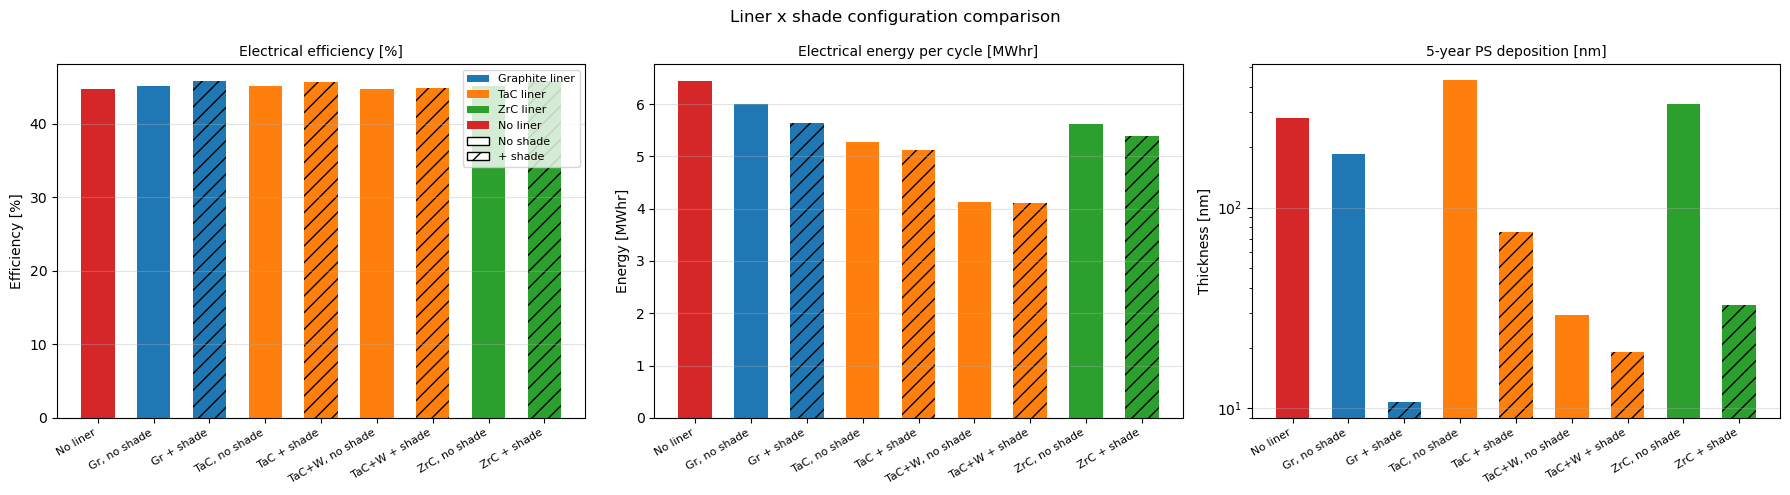

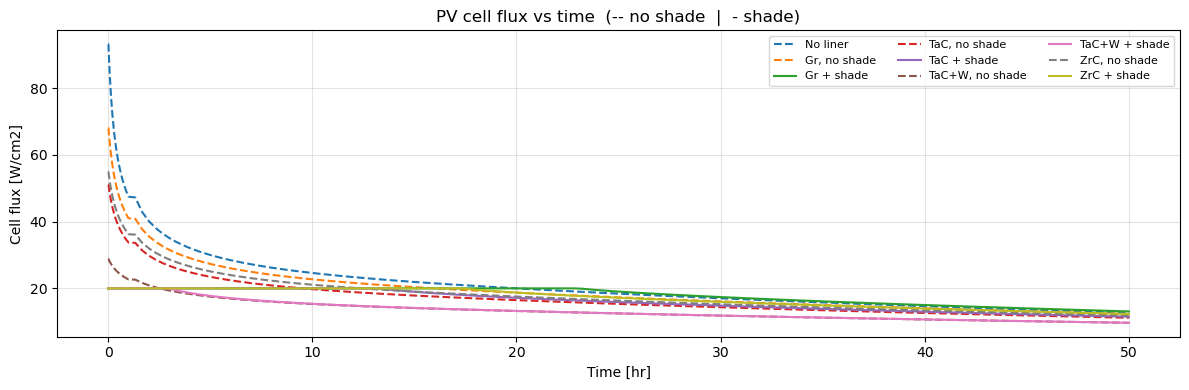

In [ ]:
# -- Scratch: liner x shade configuration comparison --------------------------
# Runs the full discharge simulation for every (liner type) x (shade on/off)
# combination and compares electrical performance and PS deposition.
# NOTE: 9 full simulations -- expect ~9x normal run time.
from thermal.deposition import deposition_rate_tinless as _dep_fn

_S_PER_YR = 3.154e7
_th_w_val  = p.get("tungsten_foil_thickness", 25e-6)

# liner_b, liner_mat, w_foil, shade_b
# shade requires a liner -- no-liner case is always no-shade
_configs = [
    dict(label="No liner",          liner_b=False, liner_mat="graphite", w_foil=False, shade_b=False),
    dict(label="Gr, no shade",      liner_b=True,  liner_mat="graphite", w_foil=False, shade_b=False),
    dict(label="Gr + shade",        liner_b=True,  liner_mat="graphite", w_foil=False, shade_b=True),
    dict(label="TaC, no shade",     liner_b=True,  liner_mat="tac",      w_foil=False, shade_b=False),
    dict(label="TaC + shade",       liner_b=True,  liner_mat="tac",      w_foil=False, shade_b=True),
    dict(label="TaC+W, no shade",   liner_b=True,  liner_mat="tac",      w_foil=True,  shade_b=False),
    dict(label="TaC+W + shade",     liner_b=True,  liner_mat="tac",      w_foil=True,  shade_b=True),
    dict(label="ZrC, no shade",     liner_b=True,  liner_mat="zrc",      w_foil=False, shade_b=False),
    dict(label="ZrC + shade",       liner_b=True,  liner_mat="zrc",      w_foil=False, shade_b=True),
]

def _run_config(liner_b, liner_mat, w_foil, shade_b):
    _block = GraphiteBlock(
        initial_temp_distribution=np.full((num_ax, num_rad), float(T_init)),
        inner_radius=r_in, outer_radius=r_out, length=L, th_ins=th_ins,
    )
    _pipe    = Pipe(OD=0.02, length=L, wall_thickness=0.001, roughness=1e-5, th_ins=0.0)
    _storage = StorageModule(
        N_pipes=1, Pipe=_pipe, Block=_block,
        num_ax_segments=num_ax, num_rad_segments=num_rad, bypass_range=[0, 1],
    )
    _ps = PowerStick(
        axial_steps=num_ax, width=side_len, height=L,
        cooling_temp=T_ps, f_bare=f_bare, f_active=f_active,
        liner_bool=liner_b, liner_width=liner_side_len,
        emissivity_table=emissivity_table,
    )
    if liner_b:
        _d_dep  = r_liner_eff - r_ps_eff
        _ar_dep = r_liner_eff / r_ps_eff
    else:
        _d_dep  = r_in - r_ps_eff
        _ar_dep = r_in / r_ps_eff
    if w_foil:
        _surf = "tungsten"
    elif liner_b and liner_mat == "tac":
        _surf = "tac"
    elif liner_b and liner_mat == "zrc":
        _surf = "zrc"
    else:
        _surf = "graphite"
    _dep_kw = dict(
        T_ps=T_ps, d=_d_dep, area_ratio=_ar_dep, surface_material=_surf,
        th_tac=liner_thickness, th_w=(_th_w_val if w_foil else 0.0),
    )
    _sim = TinlessSimulation(
        _storage, _ps,
        T_sur=T_sur, block_heat_loss=block_heat_loss_bool,
        shade_bool=shade_b,
        shade_side_len=(shade_side_len if shade_b else None),
        shade_thickness=shade_thickness,
        shade_surface_emissivity=shade_surface_emissivity,
        shade_outer_foil=shade_outer_foil,
        shade_num_conduction_layers=shade_num_conduction_layers,
        f_shade_min=(f_shade_min if shade_b else 0.0),
        f_shade_max=(f_shade_max if shade_b else 0.9),
        nominal_cell_flux=(avg_flux if shade_b else None),
        liner_material=liner_mat,
        liner_thickness=liner_thickness,
        liner_tungsten_foil=w_foil,
    )
    return _sim.run_simulation(
        end_time=end_time, dt_short=dt_short, dt_medium=dt_medium, dt_long=dt_long,
        sub_steps=sub_steps, dt_short_duration=dt_short_duration,
        deposition_fn=_dep_fn, deposition_kwargs=_dep_kw,
    )

# -- Run all configs -----------------------------------------------------------
_records = []
for _cfg in _configs:
    print(f"Running: {_cfg['label']} ...", flush=True)
    _res = _run_config(_cfg["liner_b"], _cfg["liner_mat"], _cfg["w_foil"], _cfg["shade_b"])
    _cum_Q = np.trapz(_res["Q_rad"],  _res["time"])
    _cum_P = np.trapz(_res["P_elec"], _res["time"])
    _cycles_per_yr = _S_PER_YR / (2 * _res["time"][-1])
    _records.append({
        "label":       _cfg["label"],
        "shade_b":     _cfg["shade_b"],
        "liner_mat":   _cfg["liner_mat"],
        "E_th_MWhr":   _cum_Q / 3.6e9,
        "E_el_MWhr":   _cum_P / 3.6e9,
        "eff_pct":     _cum_P / _cum_Q * 100,
        "dep_cy_nm":   _res["dep_total_nm"],
        "dep_5yr_nm":  _res["dep_total_nm"] * _cycles_per_yr * 5,
        "dep_30yr_nm": _res["dep_total_nm"] * _cycles_per_yr * 30,
        "res":         _res,
    })
    print(f"  eff={_records[-1]['eff_pct']:.2f}%  "
          f"E_el={_records[-1]['E_el_MWhr']:.3f} MWhr  "
          f"dep/cycle={_res['dep_total_nm']:.3f} nm  "
          f"30-yr={_records[-1]['dep_30yr_nm']:.2f} nm")

# -- Summary table -------------------------------------------------------------
print()
_cols = f"{'Configuration':<22}  {'E_th':>7}  {'E_el':>7}  {'Eff':>6}  {'Dep/cyc':>9}  {'5-yr':>8}  {'30-yr':>8}"
print(_cols)
print('-' * len(_cols))
for _r in _records:
    _sh = 'o' if _r["shade_b"] else '-'
    print(f"{_sh} {_r['label']:<21}  {_r['E_th_MWhr']:>6.3f}  {_r['E_el_MWhr']:>6.3f}  "
          f"{_r['eff_pct']:>5.2f}%  {_r['dep_cy_nm']:>8.3f}nm  "
          f"{_r['dep_5yr_nm']:>6.3f}nm  {_r['dep_30yr_nm']:>6.2f}nm")
print(f"{'':23}  {'MWhr':>7}  {'MWhr':>7}  {'%':>6}  {'nm':>9}  {'nm':>8}  {'nm':>8}")

# -- Bar charts ----------------------------------------------------------------
_labels  = [_r["label"]   for _r in _records]
_x       = np.arange(len(_records))

# Color by material, hatch by shade status
_mat_colors = {"graphite": "C0", "tac": "C1", "zrc": "C2"}
_no_liner_color = "C3"
_colors  = [_mat_colors.get(_r["liner_mat"], _no_liner_color)
            if _r["label"] != "No liner" else _no_liner_color
            for _r in _records]
_hatches = ["//" if _r["shade_b"] else "" for _r in _records]

fig_c, axes_c = plt.subplots(1, 3, figsize=(18, 5))
fig_c.suptitle("Liner x shade configuration comparison", fontsize=12)

_metrics = [
    (axes_c[0], [_r["eff_pct"]     for _r in _records], "Electrical efficiency [%]",         "Efficiency [%]"),
    (axes_c[1], [_r["E_el_MWhr"]   for _r in _records], "Electrical energy per cycle [MWhr]", "Energy [MWhr]"),
    (axes_c[2], [_r["dep_5yr_nm"] for _r in _records], "5-year PS deposition [nm]",         "Thickness [nm]"),
]
for _ax, _vals, _title, _ylabel in _metrics:
    _bars = _ax.bar(_x, _vals, 0.6, color=_colors)
    for _bar, _hatch in zip(_bars, _hatches):
        _bar.set_hatch(_hatch)
    _ax.set_title(_title, fontsize=10)
    _ax.set_ylabel(_ylabel)
    _ax.set_xticks(_x)
    _ax.set_xticklabels(_labels, rotation=30, ha="right", fontsize=8)
    _ax.grid(axis="y", alpha=0.35)

axes_c[2].set_yscale("log")

from matplotlib.patches import Patch
_legend = [
    Patch(facecolor="C0", label="Graphite liner"),
    Patch(facecolor="C1", label="TaC liner"),
    Patch(facecolor="C2", label="ZrC liner"),
    Patch(facecolor="C3", label="No liner"),
    Patch(facecolor="white", edgecolor="black", label="No shade"),
    Patch(facecolor="white", edgecolor="black", hatch="//", label="+ shade"),
]
axes_c[0].legend(handles=_legend, fontsize=8)

plt.tight_layout()
plt.show()

# -- Cell flux vs time overlay -------------------------------------------------
_A_cell_cm2 = 4 * side_len * L * (1 - f_bare) * f_active * 1e4
fig_p, ax_p = plt.subplots(figsize=(12, 4))
for _r in _records:
    _ls = "-" if _r["shade_b"] else "--"
    ax_p.plot(_r["res"]["time"] / 3600, _r["res"]["Q_cell"] / _A_cell_cm2,
              label=_r["label"], linestyle=_ls)
ax_p.set_xlabel("Time [hr]")
ax_p.set_ylabel("Cell flux [W/cm2]")
ax_p.set_title("PV cell flux vs time  (-- no shade  |  - shade)")
ax_p.legend(fontsize=8, ncol=3)
ax_p.grid(True, alpha=0.35)
fig_p.tight_layout()
plt.show()


Running 36 cases  (liner_sz × T_min × avg_flux = 4×3×3) ...
[discharge] T_avg=2073 K reached cutoff 2073 K at t=48.1667 hr (173400.0 s) — powerstick removed, conduction-only phase begins.
  [ 1/36] sz=1.00x  T_min=1800°C  flux=10 W/cm²  η=45.23%  dep30=0.003 μm
[discharge] T_avg=2072 K reached cutoff 2073 K at t=59.3333 hr (213600.0 s) — powerstick removed, conduction-only phase begins.
  [ 2/36] sz=1.00x  T_min=1800°C  flux=15 W/cm²  η=45.57%  dep30=0.018 μm
  [ 3/36] sz=1.00x  T_min=1800°C  flux=20 W/cm²  η=45.56%  dep30=0.040 μm
[discharge] T_avg=2173 K reached cutoff 2173 K at t=47.0000 hr (169200.0 s) — powerstick removed, conduction-only phase begins.
  [ 4/36] sz=1.00x  T_min=1900°C  flux=10 W/cm²  η=45.28%  dep30=0.004 μm
[discharge] T_avg=2171 K reached cutoff 2173 K at t=52.1667 hr (187800.0 s) — powerstick removed, conduction-only phase begins.
  [ 5/36] sz=1.00x  T_min=1900°C  flux=15 W/cm²  η=45.76%  dep30=0.027 μm
[discharge] T_avg=2172 K reached cutoff 2173 K at t=66.666

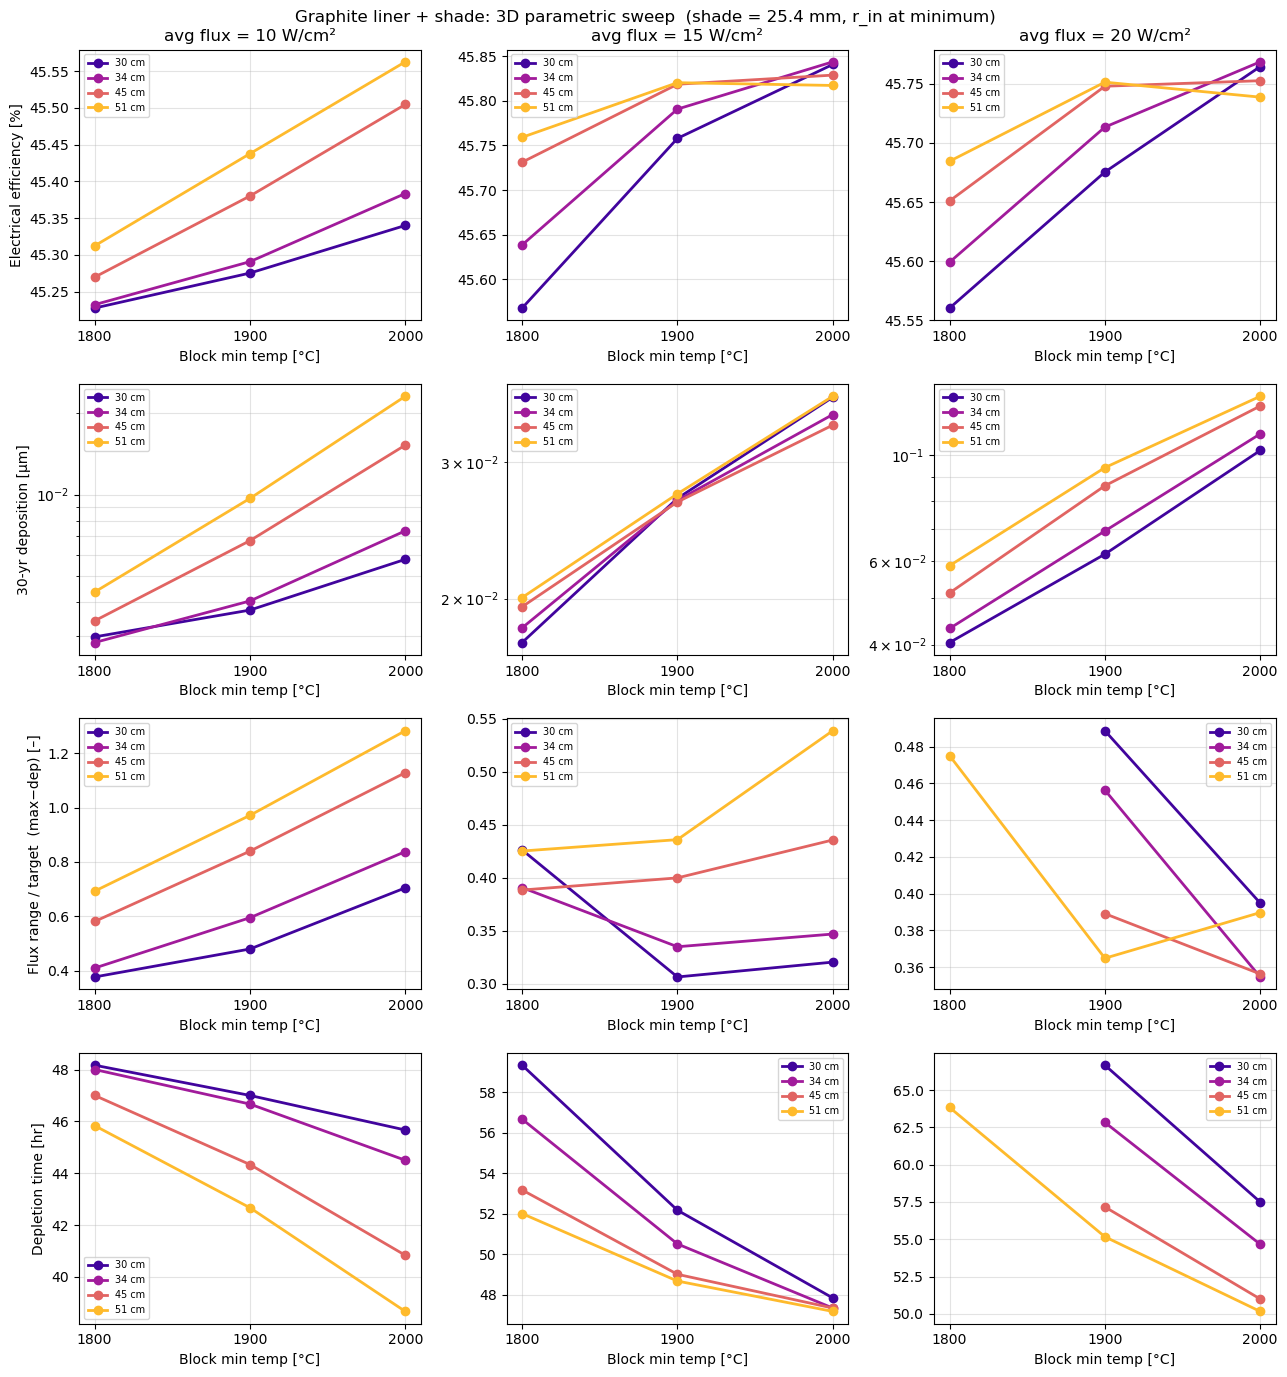

In [ ]:
# -- Parametric sweep: graphite liner + shade ----------------------------------
# 3D sweep over liner size, block minimum temperature, and average cell flux.
# Shade thickness fixed at 25.4 mm (1 inch). r_in fixed at minimum feasible.
from thermal.deposition import deposition_rate_tinless as _dep_fn
import itertools

_S_PER_YR = 3.154e7

# ── Load inputs from YAML ───────────────────────────────────────────────────────────────────────
with open('tinless_model_input.yaml') as _f:
    _cfg = yaml.safe_load(_f)
_s = _cfg['storage']
_p = _cfg['powerstick']
_sh = _cfg.get('shade', {})

end_time             = _cfg['end_time']
T_sur                = _cfg['T_sur']
block_heat_loss_bool = _cfg['block_heat_loss_bool']
dt_medium         = _cfg['dt_medium']
dt_long           = _cfg['dt_long']
dt_short_duration = _cfg.get('dt_short_duration', 3600)
sub_steps         = _cfg['sub_steps']

avg_flux         = _s['avg_flux']
duration_hr      = _s['duration_hr']
T_min            = _s['T_min']
block_temp_range = _s['block_temp_range']
L                = _s['L']
th_ins           = _s['th_ins']
num_ax           = _s['num_ax_segments']
num_rad          = _s['num_rad_segments']

side_len       = _p['side_len']
area_ratio     = _p['area_ratio']
f_bare         = _p['f_bare']
f_active       = _p['f_active']
T_ps           = _p['cooling_temp']
liner_side_len = _p['liner_side_len']

corner_gap                   = _sh.get('corner_gap', 0.003175)
shade_surface_emissivity     = _sh.get('surface_emissivity', 0.8)
shade_outer_foil             = _sh.get('outer_foil', False)
shade_num_conduction_layers  = _sh.get('num_conduction_layers', 5)

raw_emis = _cfg['emissivity_tables'][0]['value']
emissivity_table = [(tuple(row[0]), float(row[1]), float(row[2]), float(row[3]))
                    for row in raw_emis]

r_ps_eff    = 2 * side_len / np.pi
r_liner_eff = 2 * liner_side_len / np.pi
r_in        = r_ps_eff * area_ratio
A_ps        = 4 * side_len * L
T_avg_      = T_min + block_temp_range / 2
f_cell_     = (1.0 - f_bare) * f_active
f_inact_    = (1.0 - f_bare) * (1.0 - f_active)
_ps_tmp     = PowerStick(axial_steps=1, width=side_len, height=L,
                         cooling_temp=T_ps, f_bare=f_bare, f_active=f_active,
                         liner_bool=True, liner_width=liner_side_len,
                         emissivity_table=emissivity_table)
_inc_bins, _, _ = _ps_tmp.incident_energy(T_min - 100, 1 / area_ratio)
_inc_tot    = sum(_inc_bins.values())
f_Q_        = sum(
    _inc_bins[row[0]] / _inc_tot * f_cell_ * row[1]
    / (f_bare * row[2] + f_cell_ * row[1] + f_inact_ * row[3])
    for row in emissivity_table)
E_req       = avg_flux * 1e4 * A_ps * f_cell_ / f_Q_ * duration_hr * 3600
e_dens      = storage_rho(T_avg_) * storage_cp(T_avg_) * block_temp_range
V_block     = E_req / e_dens
r_out       = np.sqrt(V_block / (np.pi * L) + r_in**2)

# ── sweep ranges ────────────────────────────────────────────────────────────────────────────────────────
_liner_sz_factors = [1.00, 1.15, 1.50, 1.70]   # scale on liner_side_len / r_liner_eff
_T_min_C_vals     = [1800, 1900, 2000]           # block minimum (cutoff) temperature [C]
_avg_flux_vals    = [10, 15, 20]                 # nominal cell flux [W/cm²]
_SHADE_TH_FIXED   = 25.4e-3                      # shade thickness fixed at 1 inch = 25.4 mm
_LINER_TH_FIXED   = 0.01                         # liner wall thickness fixed at 1 cm
_R_IN_F_FIXED     = 1.01                         # r_in safety margin on liner clearance

def _run_gr_shade(liner_sz_f=1.0, T_min_K=None, avg_flux_Wcm2=None):
    _T_min    = T_min_K             if T_min_K       is not None else T_min
    _avg_flux = avg_flux_Wcm2 if avg_flux_Wcm2 is not None else avg_flux

    _shade_th = _SHADE_TH_FIXED
    _l_sz     = liner_side_len * liner_sz_f
    _r_lin    = r_liner_eff    * liner_sz_f

    # Shade at minimum physically-valid position for this liner.
    _r_shade_new  = (1.0 + np.sqrt(2) / 2.0) * _r_lin
    _shade_sl_new = _r_shade_new * np.pi / 2.0

    # f_shade limits for this shade geometry.
    _shade_perim = 4.0 * _shade_sl_new
    _f_shade_min = 8.0 * _shade_th / _shade_perim
    _f_shade_max = 1.0 - 8.0 * corner_gap / _shade_perim

    # Block sized for this case: r_in from liner geometry, r_out from energy balance.
    _r_in_use    = _R_IN_F_FIXED * (1.0 + np.sqrt(2)) * _r_lin
    _T_avg_case  = _T_min + block_temp_range / 2
    _E_req_case  = _avg_flux * 1e4 * A_ps * f_cell_ / f_Q_ * duration_hr * 3600
    _e_dens_case = storage_rho(_T_avg_case) * storage_cp(_T_avg_case) * block_temp_range
    _r_out_use   = np.sqrt(_E_req_case / _e_dens_case / (np.pi * L) + _r_in_use**2)

    _block = GraphiteBlock(
        initial_temp_distribution=np.full((num_ax, num_rad), float(_T_min + 500.0)),
        inner_radius=_r_in_use, outer_radius=_r_out_use, length=L, th_ins=th_ins,
    )
    _pipe    = Pipe(OD=0.02, length=L, wall_thickness=0.001, roughness=1e-5, th_ins=0.0)
    _storage = StorageModule(
        N_pipes=1, Pipe=_pipe, Block=_block,
        num_ax_segments=num_ax, num_rad_segments=num_rad, bypass_range=[0, 1],
    )
    _ps = PowerStick(
        axial_steps=num_ax, width=side_len, height=L,
        cooling_temp=T_ps, f_bare=f_bare, f_active=f_active,
        liner_bool=True, liner_width=_l_sz,
        emissivity_table=emissivity_table,
    )
    _dep_kw = dict(
        T_ps=T_ps, d=_r_lin - r_ps_eff,
        area_ratio=(1.0 + np.sqrt(2)) * _r_lin / r_ps_eff,
        surface_material='graphite', th_tac=0.0, th_w=0.0,
    )
    _sim = TinlessSimulation(
        _storage, _ps,
        T_sur=T_sur, block_heat_loss=block_heat_loss_bool,
        shade_bool=True,
        shade_side_len=_shade_sl_new,
        shade_thickness=_shade_th,
        shade_surface_emissivity=shade_surface_emissivity,
        shade_outer_foil=shade_outer_foil,
        shade_num_conduction_layers=shade_num_conduction_layers,
        f_shade_min=_f_shade_min,
        f_shade_max=_f_shade_max,
        nominal_cell_flux=_avg_flux,
        liner_material='graphite',
        liner_thickness=_LINER_TH_FIXED,
        liner_tungsten_foil=False,
    )
    # Cap sweep end_time at 2x duration_hr so slow-discharge cases return NaN quickly.
    #_sweep_end = min(end_time, 2 * duration_hr * 3600)
    _sweep_end = end_time
    _res = _sim.run_simulation(
        end_time=_sweep_end, dt_short=dt_medium, dt_medium=dt_medium, dt_long=dt_long,
        sub_steps=sub_steps, dt_short_duration=dt_short_duration,
        deposition_fn=_dep_fn, deposition_kwargs=_dep_kw,
        T_ps_cutoff=_T_min,
        stop_at_cutoff=True,
    )
    _cum_Q  = np.trapz(_res['Q_rad'],  _res['time'])
    _cum_P  = np.trapz(_res['P_elec'], _res['time'])
    _cyc_yr = _S_PER_YR / (2 * _res['time'][-1])
    _t_ps     = _res.get('t_ps_removed')
    _A_active = 4 * side_len * L * f_active
    _flux_arr = np.array(_res['Q_cell']) / _A_active / 1e4
    if _t_ps is not None:
        _idx_dep      = max(0, np.searchsorted(_res['time'], _t_ps, side='right') - 1)
        _flux_dep     = float(_flux_arr[_idx_dep])
        _flux_max     = float(np.nanmax(_flux_arr))
        _flux_rng_rel = (_flux_max - _flux_dep) / _avg_flux
        _t_dep_hr     = _t_ps / 3600.0
    else:
        _flux_rng_rel = float('nan')
        _t_dep_hr     = float('nan')
    return {
        'eff_pct':        _cum_P / _cum_Q * 100,
        'dep_30yr_nm':    _res['dep_total_nm'] * _cyc_yr * 30,
        'flux_range_rel': _flux_rng_rel,
        't_dep_hr':       _t_dep_hr,
    }

# ── run 3D sweep (36 cases) ───────────────────────────────────────────────────────────────────────────────────────
_cases = list(itertools.product(
    enumerate(_liner_sz_factors),
    enumerate(_T_min_C_vals),
    enumerate(_avg_flux_vals),
))
_n = len(_cases)
print(f'Running {_n} cases  '
      f'(liner_sz × T_min × avg_flux = '
      f'{len(_liner_sz_factors)}×{len(_T_min_C_vals)}×{len(_avg_flux_vals)}) ...', flush=True)

_results_3d = {}   # keyed by (i_sz, i_tm, i_fl)
for _k, ((i_sz, _sz_f), (i_tm, _tm_C), (i_fl, _fl)) in enumerate(_cases):
    _r = _run_gr_shade(liner_sz_f=_sz_f, T_min_K=_tm_C + 273.15, avg_flux_Wcm2=_fl)
    _results_3d[(i_sz, i_tm, i_fl)] = _r
    print(f'  [{_k+1:2d}/{_n}] sz={_sz_f:.2f}x  T_min={_tm_C:.0f}°C  flux={_fl:.0f} W/cm²  '
          f'η={_r["eff_pct"]:.2f}%  dep30={_r["dep_30yr_nm"]:.3f} nm', flush=True)

# ── plots ────────────────────────────────────────────────────────────────────────────────────────────────
# rows = [efficiency, deposition, P at depletion, depletion time]
# cols = avg_flux panels, lines = liner_sz, x-axis = T_min_C
import matplotlib.cm as cm

_sz_colors = cm.plasma(np.linspace(0.1, 0.85, len(_liner_sz_factors)))
_fig, _axes = plt.subplots(4, 3, figsize=(13, 14))
_fig.suptitle(
    'Graphite liner + shade: 3D parametric sweep  '
    '(shade = 25.4 mm, r_in at minimum)',
    fontsize=12,
)

for col, (i_fl, _fl) in enumerate(zip(range(len(_avg_flux_vals)), _avg_flux_vals)):
    ax_e  = _axes[0, col]
    ax_d  = _axes[1, col]
    ax_en = _axes[2, col]
    ax_pk = _axes[3, col]

    for i_sz, (_sz_f, _col) in enumerate(zip(_liner_sz_factors, _sz_colors)):
        _effs  = [_results_3d[(i_sz, i_tm, i_fl)]['eff_pct']     for i_tm in range(len(_T_min_C_vals))]
        _deps  = [_results_3d[(i_sz, i_tm, i_fl)]['dep_30yr_um'] for i_tm in range(len(_T_min_C_vals))]
        _franges = [_results_3d[(i_sz, i_tm, i_fl)]['flux_range_rel'] for i_tm in range(len(_T_min_C_vals))]
        _tdeps   = [_results_3d[(i_sz, i_tm, i_fl)]['t_dep_hr']       for i_tm in range(len(_T_min_C_vals))]
        _lbl     = f'{liner_side_len * _sz_f * 100:.0f} cm'
        ax_e.plot( _T_min_C_vals, _effs,   'o-', color=_col, lw=2, label=_lbl)
        ax_d.plot( _T_min_C_vals, _deps,   'o-', color=_col, lw=2, label=_lbl)
        ax_en.plot(_T_min_C_vals, _franges, 'o-', color=_col, lw=2, label=_lbl)
        ax_pk.plot(_T_min_C_vals, _tdeps,  'o-', color=_col, lw=2, label=_lbl)

    ax_e.set_title(f'avg flux = {_fl} W/cm²')
    for _ax in (ax_e, ax_d, ax_en, ax_pk):
        _ax.set_xlabel('Block min temp [°C]')
        _ax.set_xticks(_T_min_C_vals)
        _ax.grid(True, alpha=0.35)
        _ax.legend(fontsize=7)
    ax_d.set_yscale('log')
    ax_d.grid(True, alpha=0.35, which='both')
    if col == 0:
        ax_e.set_ylabel('Electrical efficiency [%]')
        ax_d.set_ylabel('30-yr deposition [μm]')
        ax_en.set_ylabel('Flux range / target  (max−dep) [–]')
        ax_pk.set_ylabel('Depletion time [hr]')

plt.tight_layout()
plt.show()


0.44999999999999996
